# ED experiments

## Single time

In [1]:
import utils.multiproductf as mpf

ks, coefficients, cost = mpf.search_mpf_coefficients_ccost(21, 30, 2, 2, mpf.a_onenorm_cost)
print(ks[:5])
print(coefficients[:5])
print(cost[:5])

[[21 30]
 [21 29]
 [22 30]
 [21 28]
 [22 29]]
[[-0.96078431  1.96078431]
 [-1.1025      2.1025    ]
 [-1.16346154  2.16346154]
 [-1.28571429  2.28571429]
 [-1.3557423   2.3557423 ]]
[2.92156863 3.205      3.32692308 3.57142857 3.71148459]


In [2]:
# import utils.multiproductf as mpf
# import numpy as np

# ks = [5, 6, 10]
# coefficients, costs = mpf.mpfcoeffs_sergiy(ks, 8, 2)
# print(coefficients)
# print(np.sum(np.abs(coefficients)))

# ks = np.array([ks])
# coefficients = np.array([coefficients])

In [3]:
# from juliacall import Main as jl, convert as jlconvert
# import numpy as np
# import juliacall

# path_to_julia_tn = "../../z2chain/Z2HiggsChainDynamics.jl"
# path_to_julia_mpf = "../../utils/MultiProductF.jl"
# jl.seval(f"include(\"{path_to_julia_tn}\")")
# jl.seval(f"include(\"{path_to_julia_mpf}\")")
# jl.seval("using .Z2HiggsChainDynamics")
# jl.seval("using .MultiProductF")

# ks, coefficients, cost = jl.MultiProductF.search_mpf_parameters_ccost(30, 43, 2, 2, jl.MultiProductF.k_a_onenorm_cost)

# ks = np.array(ks)
# coefficients = np.array(coefficients)
# cost = np.array(cost)

# print(ks[:5])
# print(coefficients[:5])
# print(cost[:5])

In [4]:
import utils.multiproductf as mpf
import z2chain.exact as exact
import numpy as np

L = 5
m = 2
g = 0.8
lamb = 1
t = 5

max_trotter_layers = 40

initial_state = np.zeros(2**L, dtype=complex)
initial_state[0] = 1.0

particle_position = 2

# mpf_ks = [
#     [1, 2],
#     [1, 2, 3],
#     [1, 2, 4],
#     [1, 2, 5],
#     [1, 2, 6],
#     [1, 3, 6],
#     [1, 3, 7]
# ]

mpf_ks = np.array([ks[0, :]])

# mpf_coeffs = [mpf.mpfcoeffs(ks, 2)[0] for ks in mpf_ks]
mpf_coeffs = np.array([coefficients[0, :]])

t2_depths = list(range(1, max_trotter_layers+1))
mpf2_depths = [max(ks) for ks in mpf_ks]

exact_observables = exact.singlep_quench_simulation(L, m, g, lamb, particle_position, t, 1)[-1]
t2_observables = np.array([exact.singlep_quench_trotter2_simulation(L, m, g, lamb, particle_position, t/i, i)[-1] for i in t2_depths])
mpf2_observables = np.array([exact.singlep_quench_mpf2_simulation_single_t(L, m, g, lamb, particle_position, ks, coeffs, t) for ks, coeffs in zip(mpf_ks, mpf_coeffs)])

t2_deviations = np.mean(np.abs(t2_observables - exact_observables), axis=1)
mpf2_deviations = np.mean(np.abs(mpf2_observables - exact_observables), axis=1)

/opt/homebrew/Caskroom/miniconda/base/envs/qiskit/lib/python3.12/site-packages/scipy/sparse/_index.py:108: SparseEfficiencyWarning: Changing the sparsity structure of a csc_matrix is expensive. lil_matrix is more efficient.
  self._set_intXint(row, col, x.flat[0])


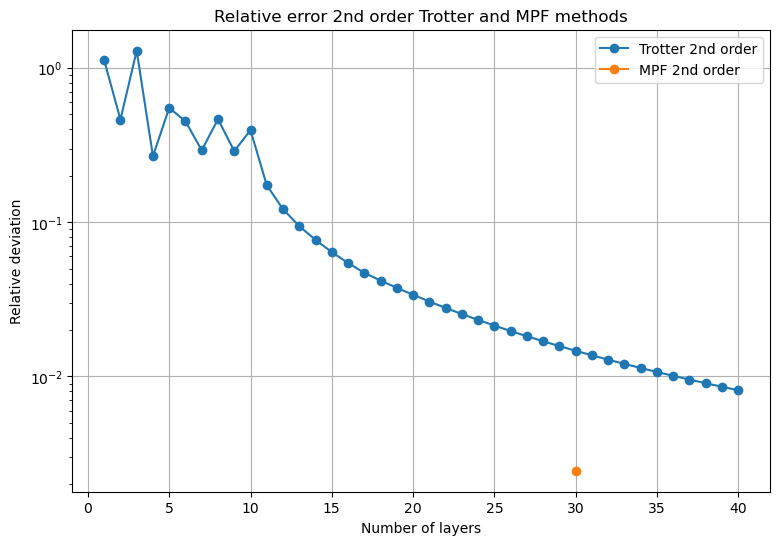

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

plt.plot(t2_depths, t2_deviations, label='Trotter 2nd order', marker='o')
plt.plot(mpf2_depths, mpf2_deviations, label='MPF 2nd order', marker='o')
plt.yscale('log')
plt.xlabel('Number of layers')
plt.ylabel('Relative deviation')
plt.title('Relative error 2nd order Trotter and MPF methods')
plt.grid()
plt.legend()

## Controlling Trotter error

In order for MPFs to work, the following condition must hold:

$$\varepsilon_{\mathrm{PF}} = \frac{t^{p+1} \alpha_{\mathrm{comm}}}{k_1^p} < 1$$

Otherwise MPFs amplify errors instead of supressing it, because the error in MPFs for long $t$ is

$$\varepsilon_{\mathrm{MPF}} = 2\left(t^{p+1} \alpha_{\mathrm{comm}}\right)^2 \sum_{i=1}^r \frac{|a_i|}{k_i^{2p}} \leq 2\varepsilon_{\mathrm{PF}}^2 \sum_{i=1}^r |a_i|$$

$\varepsilon_{\mathrm{PF}}$ is the error of a product formula of order $p$ with depth $k_1$. Notice how this quantity appears in the error of the MPF squared after factorization. If the condition above does not hold, the Trotter error gets amplified.

In [25]:
from multiprocessing import Pool, cpu_count
import utils.multiproductf as mpf
import matplotlib.pyplot as plt
import numpy as np

def mpf_error(t, ks, coeffs, pf_order, alpha_comm):
    return 2*(t**(pf_order+1)*alpha_comm)**2*np.sum(np.abs(coeffs)/ks**(2*pf_order))

def mpf_min_k_improvement(t_arr, alpha_comm, pf_order):
    return np.ceil(t_arr**(1+1/pf_order)*alpha_comm**(1/pf_order)).astype(int)

def plot_mpf_min_k_improvement(t_arr, alpha_comm, pf_order):
    plt.rc("text", usetex=True)
    plt.rc("font", size=20, family="serif", weight="bold")
    cmap = plt.get_cmap("Set2")
    fig, ax = plt.subplots(figsize=(9, 6))
    plt.plot(t_arr, mpf_min_k_improvement(t_arr, alpha_comm, pf_order), "o--", markersize=10, markeredgecolor="black", color=cmap(0), label='MPF min k improvement')
    plt.xlabel(r"$t$")
    plt.ylabel(r"$k_{min}$")
    plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    plt.show()
    plt.rcdefaults()

def get_ks_coeffs_improvement(t_arr, alpha_comm, nks, anorm_max, pf_order):
    min_ks = mpf_min_k_improvement(t_arr, alpha_comm, pf_order)
    ks_improvement = np.zeros((len(t_arr), nks), dtype=int)
    coeffs_improvement = np.zeros((len(t_arr), nks))
    for i, t in enumerate(t_arr):
        ks_improvement[i, :], coeffs_improvement[i, :], this_costs = mpf.search_mpf_coefficients_anorm_max(min_ks[i], anorm_max, nks, pf_order, mpf.k_a_onenorm_cost)
    return ks_improvement, coeffs_improvement

def get_ks_maxk_dt(t_arr, max_k_dt, nks, anorm_max, pf_order):
    ks_matrix = np.zeros((len(t_arr), nks), dtype=int)
    coeffs_matrix = np.zeros((len(t_arr), nks))
    for i, t in enumerate(t_arr):
        k_max = int(np.ceil(t_arr[i] / max_k_dt))
        ks_matrix[i, :], coeffs_matrix[i, :], this_costs = mpf.search_mpf_coefficients_anorm_max_kmax(k_max, anorm_max, nks, pf_order, mpf.k_a_onenorm_cost)
    # with Pool(processes=cpu_count()) as pool:
    #     results = pool.starmap(mpf.search_mpf_coefficients_anorm_max_kmax, [(int(np.ceil(t / max_k_dt)), anorm_max, nks, pf_order, mpf.k_a_onenorm_cost) for t in t_arr])
    # ks_matrix = np.array(results)
    return ks_matrix, coeffs_matrix

def plot_mpf_ks(ks, x_arr=None, x_label=None, y_label=None, nticks=5, filepath=""):
    plt.rc("text", usetex=True)
    plt.rc("font", size=20, family="serif", weight="bold")
    cmap = plt.get_cmap("Set2")
    fig, ax = plt.subplots(figsize=(9, 6))
    if x_arr is not None:
        if len(x_arr) != ks.shape[0]:
            raise ValueError("x_arr must have the same length as the number of rowss in ks.")
    else:
        x_arr = np.arange(ks.shape[0])
    x_ticks = np.linspace(0, x_arr[-1], nticks)
    for i in range(ks.shape[1]):
        plt.plot(x_arr, ks[:, i], "o--", markersize=10, markeredgecolor="black", color=cmap(i % 8), label=r"MPF PF_{%i} Layers" % (i + 1))
    plt.xticks(x_ticks)
    plt.xlabel(x_label if x_label is not None else "Sim. index", labelpad=10)
    plt.ylabel("Layers" if y_label is None else y_label, labelpad=10)
    plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    plt.tight_layout()
    if filepath:
        plt.savefig(filepath, facecolor="none", dpi=300)
    plt.show()
    plt.rcdefaults()

def plt_mpf_conventional_comparison(x_arr, ks, dt, depth_factor=1, x_label=None, y_label=None, title="", nticks=5, filepath=""):
    if len(x_arr) != ks.shape[0]:
        raise ValueError("x_arr must have the same length as the number of rows in ks.")
    conventional_depth = np.ceil(x_arr / dt).astype(int)

    plt.rc("text", usetex=True)
    plt.rc("font", size=20, family="serif", weight="bold")
    cmap = plt.get_cmap("Set2")
    fig, ax = plt.subplots(figsize=(9, 6))
    x_ticks = np.linspace(0, x_arr[-1], nticks)
    for i in range(ks.shape[1]):
        plt.plot(x_arr, ks[:, i], "o--", markersize=10, markeredgecolor="black", color=cmap(i % 8), label=r"MPF $\mathrm{PF}_{%i}$ Layers" % (i + 1))
    plt.plot(x_arr, conventional_depth, "o--", markersize=10, markeredgecolor="black", color=cmap((i+1) % 8), label=r"Conventional $\mathrm{PF}_{%i}$ Layers" % (depth_factor))
    plt.xticks(x_ticks)
    plt.xlabel(x_label if x_label is not None else "Sim. index", labelpad=10)
    plt.ylabel("Layers" if y_label is None else y_label, labelpad=10)
    plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if title:
        plt.title(title)
    plt.legend(shadow=True, fontsize=12)
    plt.tight_layout()
    if filepath:
        plt.savefig(filepath, facecolor="none", dpi=300)
    plt.show()
    plt.rcdefaults()

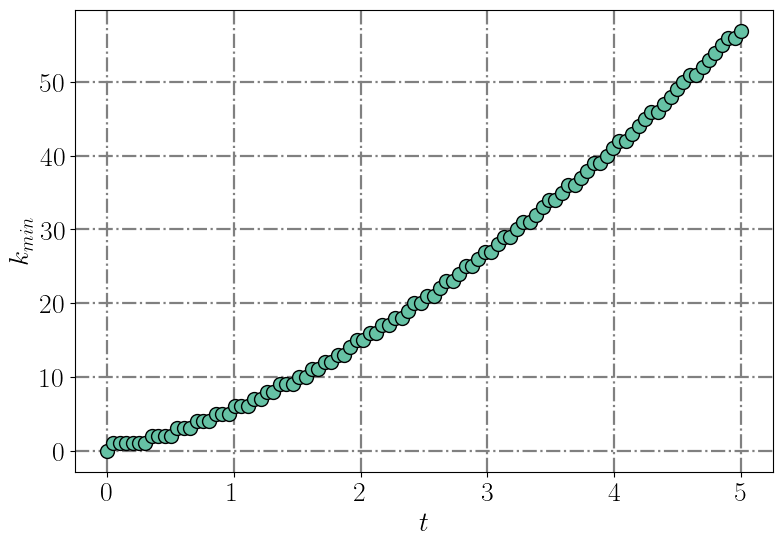

In [7]:
from z2chain.circs import alpha_commutator

plot_mpf_min_k_improvement(np.linspace(0, 5, 100), float(alpha_commutator(L, m, g, lamb)), 2)

[[ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 1  2]
 [ 2  4]
 [ 2  4]
 [ 2  4]
 [ 2  4]
 [ 2  4]
 [ 3  5]
 [ 3  5]
 [ 3  5]
 [ 3  5]
 [ 3  5]
 [ 4  6]
 [ 4  6]
 [ 4  6]
 [ 4  6]
 [ 4  6]
 [ 5  8]
 [ 5  8]
 [ 5  8]
 [ 5  8]
 [ 6  9]
 [ 6  9]
 [ 6  9]
 [ 6  9]
 [ 7 10]
 [ 7 10]
 [ 7 10]
 [ 8 12]
 [ 8 12]
 [ 8 12]
 [ 8 12]
 [ 9 13]
 [ 9 13]
 [ 9 13]
 [10 15]
 [10 15]
 [10 15]
 [11 16]
 [11 16]
 [11 16]
 [12 17]]
[[-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.33333333  1.33333333]
 [-0.5625      1.5625    ]
 [-0.5625      1.5625    ]
 [-0.5625      1.5625    ]
 [-0.5625      1.5625    ]


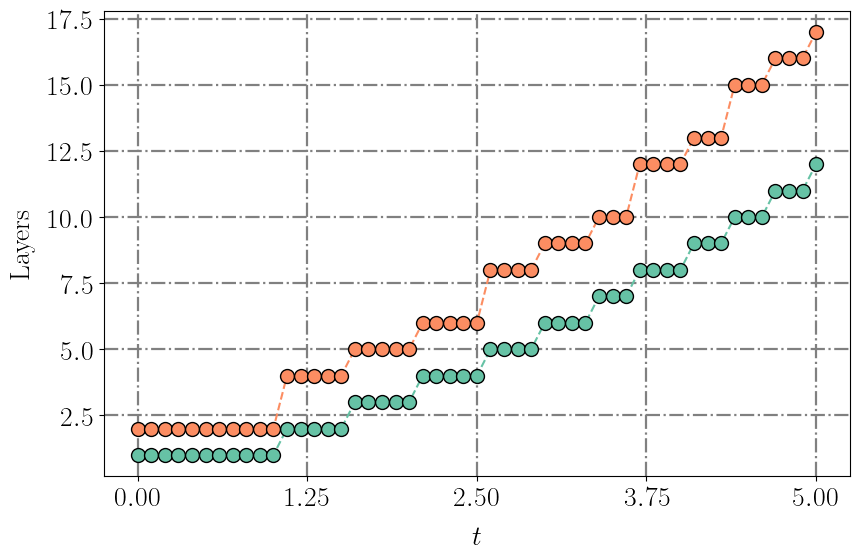

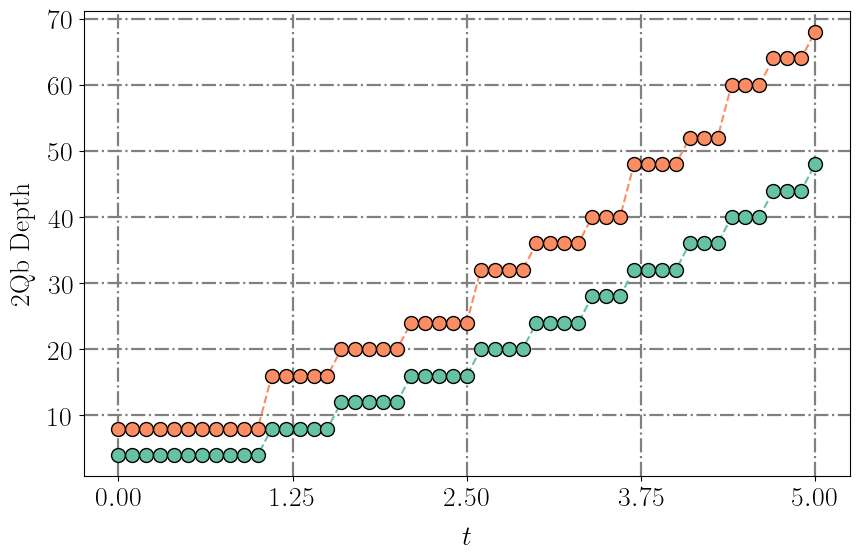

In [8]:
t_arr = np.linspace(0, 5, 51)
ks, coeffs = get_ks_coeffs_improvement(t_arr, 1, 2, 3, 2)
print(ks)
print(coeffs)
plot_mpf_ks(ks, t_arr, x_label=r"$t$")
plot_mpf_ks(4*ks, t_arr, x_label=r"$t$", y_label=r"2Qb Depth")

# All times

## Simulation settings

In [23]:
from z2chain.circs import trotter_dt
import utils.multiproductf as mpf
import z2chain.exact as exact
import numpy as np

L = 5
m = 2
g = 0.8
lamb = 1

final_time = 5
# dt = trotter_dt(1e-2, L, m, g, lamb)
dt = 0.125
steps = int(np.ceil(final_time / dt))

particle_position = 2

x_basis = False

print(f"{steps=}")

steps=40


## Ensuring MPF improvement

### Ensured inprovement

ɑ^(1/2) = 5.075431016179809


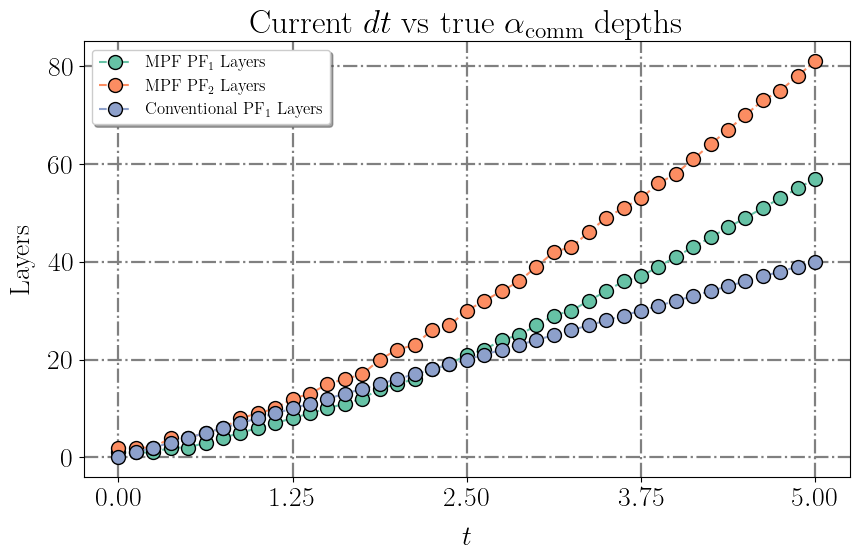

In [26]:
from z2chain.circs import alpha_commutator
import numpy as np

alpha_comm = float(alpha_commutator(L, m, g, lamb))
print(f"ɑ^(1/2) = {np.sqrt(alpha_comm)}")

t_arr = np.linspace(0, 5, steps+1)
ks, coeffs = get_ks_coeffs_improvement(t_arr, alpha_comm, 2, 3, 2)

plt_mpf_conventional_comparison(t_arr, ks, dt, 1, x_label=r"$t$", title=r"Current $dt$ vs true $\alpha_{\mathrm{comm}}$ depths")

### Maintaining lower depth

In [27]:
from z2chain.circs import nlayers_trotter, alpha_commutator

desired_precision = 1e-2

max_pf_layers = int(np.ceil(final_time / dt))
required_pf_layers = int(np.ceil(nlayers_trotter(final_time, desired_precision, L, m, g, lamb)))
beta_factor = max_pf_layers / required_pf_layers
original_alpha_comm = alpha_commutator(L, m, g, lamb)
alpha_comm_tilde = desired_precision * beta_factor**2 * required_pf_layers**2 / final_time**3
print(f"With the provided dt, the max Trotter layers is {max_pf_layers}.")
print(f"To achieve the desired precision, the required Trotter layers is {required_pf_layers}.")
print(f"Beta factor = {beta_factor}")
print(f"Original ɑ = {original_alpha_comm}")
print(f"New ɑ = {alpha_comm_tilde}")

With the provided dt, the max Trotter layers is 40.
To achieve the desired precision, the required Trotter layers is 568.
Beta factor = 0.07042253521126761
Original ɑ = 25.7600000000000
New ɑ = 0.12800000000000003


ɑ_true = 25.760000000000005


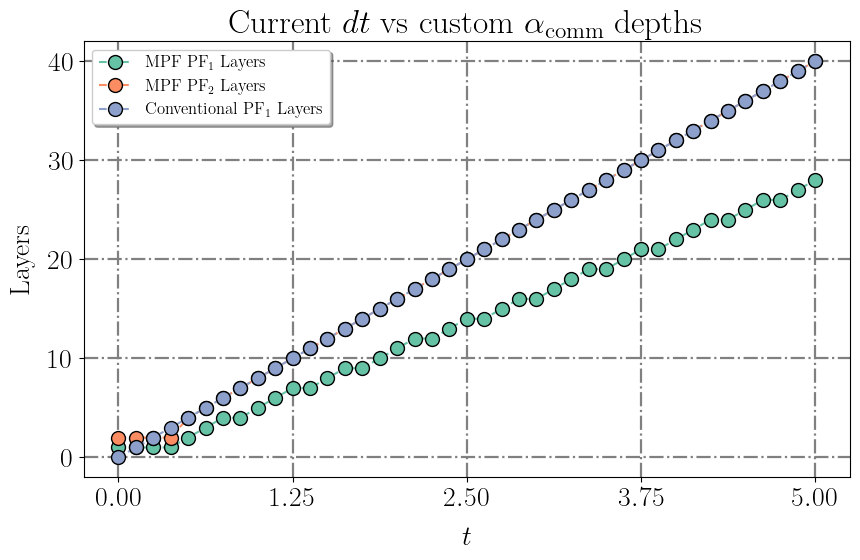

In [28]:
from z2chain.circs import alpha_commutator
import numpy as np

alpha_comm = float(alpha_commutator(L, m, g, lamb))
print(f"ɑ_true = {alpha_comm}")

# custom_alpha_comm = alpha_comm
custom_alpha_comm = 3.5

t_arr = np.linspace(0, final_time, steps+1)
# ks, coeffs = get_ks_coeffs_improvement(t_arr, custom_alpha_comm, 2, 3, 2)
ks, coeffs = get_ks_maxk_dt(t_arr, dt, 2, 3, 2)

plt_mpf_conventional_comparison(t_arr, ks, dt, 1, x_label=r"$t$", title=r"Current $dt$ vs custom $\alpha_{\mathrm{comm}}$ depths")

## Simulation

In [29]:
import utils.multiproductf as mpf
import z2chain.exact as exact
import numpy as np

exact_observables = exact.singlep_quench_simulation(L, m, g, lamb, particle_position, dt, steps)
t2_observables = exact.singlep_quench_trotter2_simulation(L, m, g, lamb, particle_position, dt, steps)
mpf2_observables = exact.singlep_quench_mpf2_simulation(L, m, g, lamb, particle_position, ks[1::], coeffs[1::], dt)

t2_deviations = np.mean(np.abs(t2_observables - exact_observables), axis=1)
mpf2_deviations = np.mean(np.abs(mpf2_observables - exact_observables), axis=1)

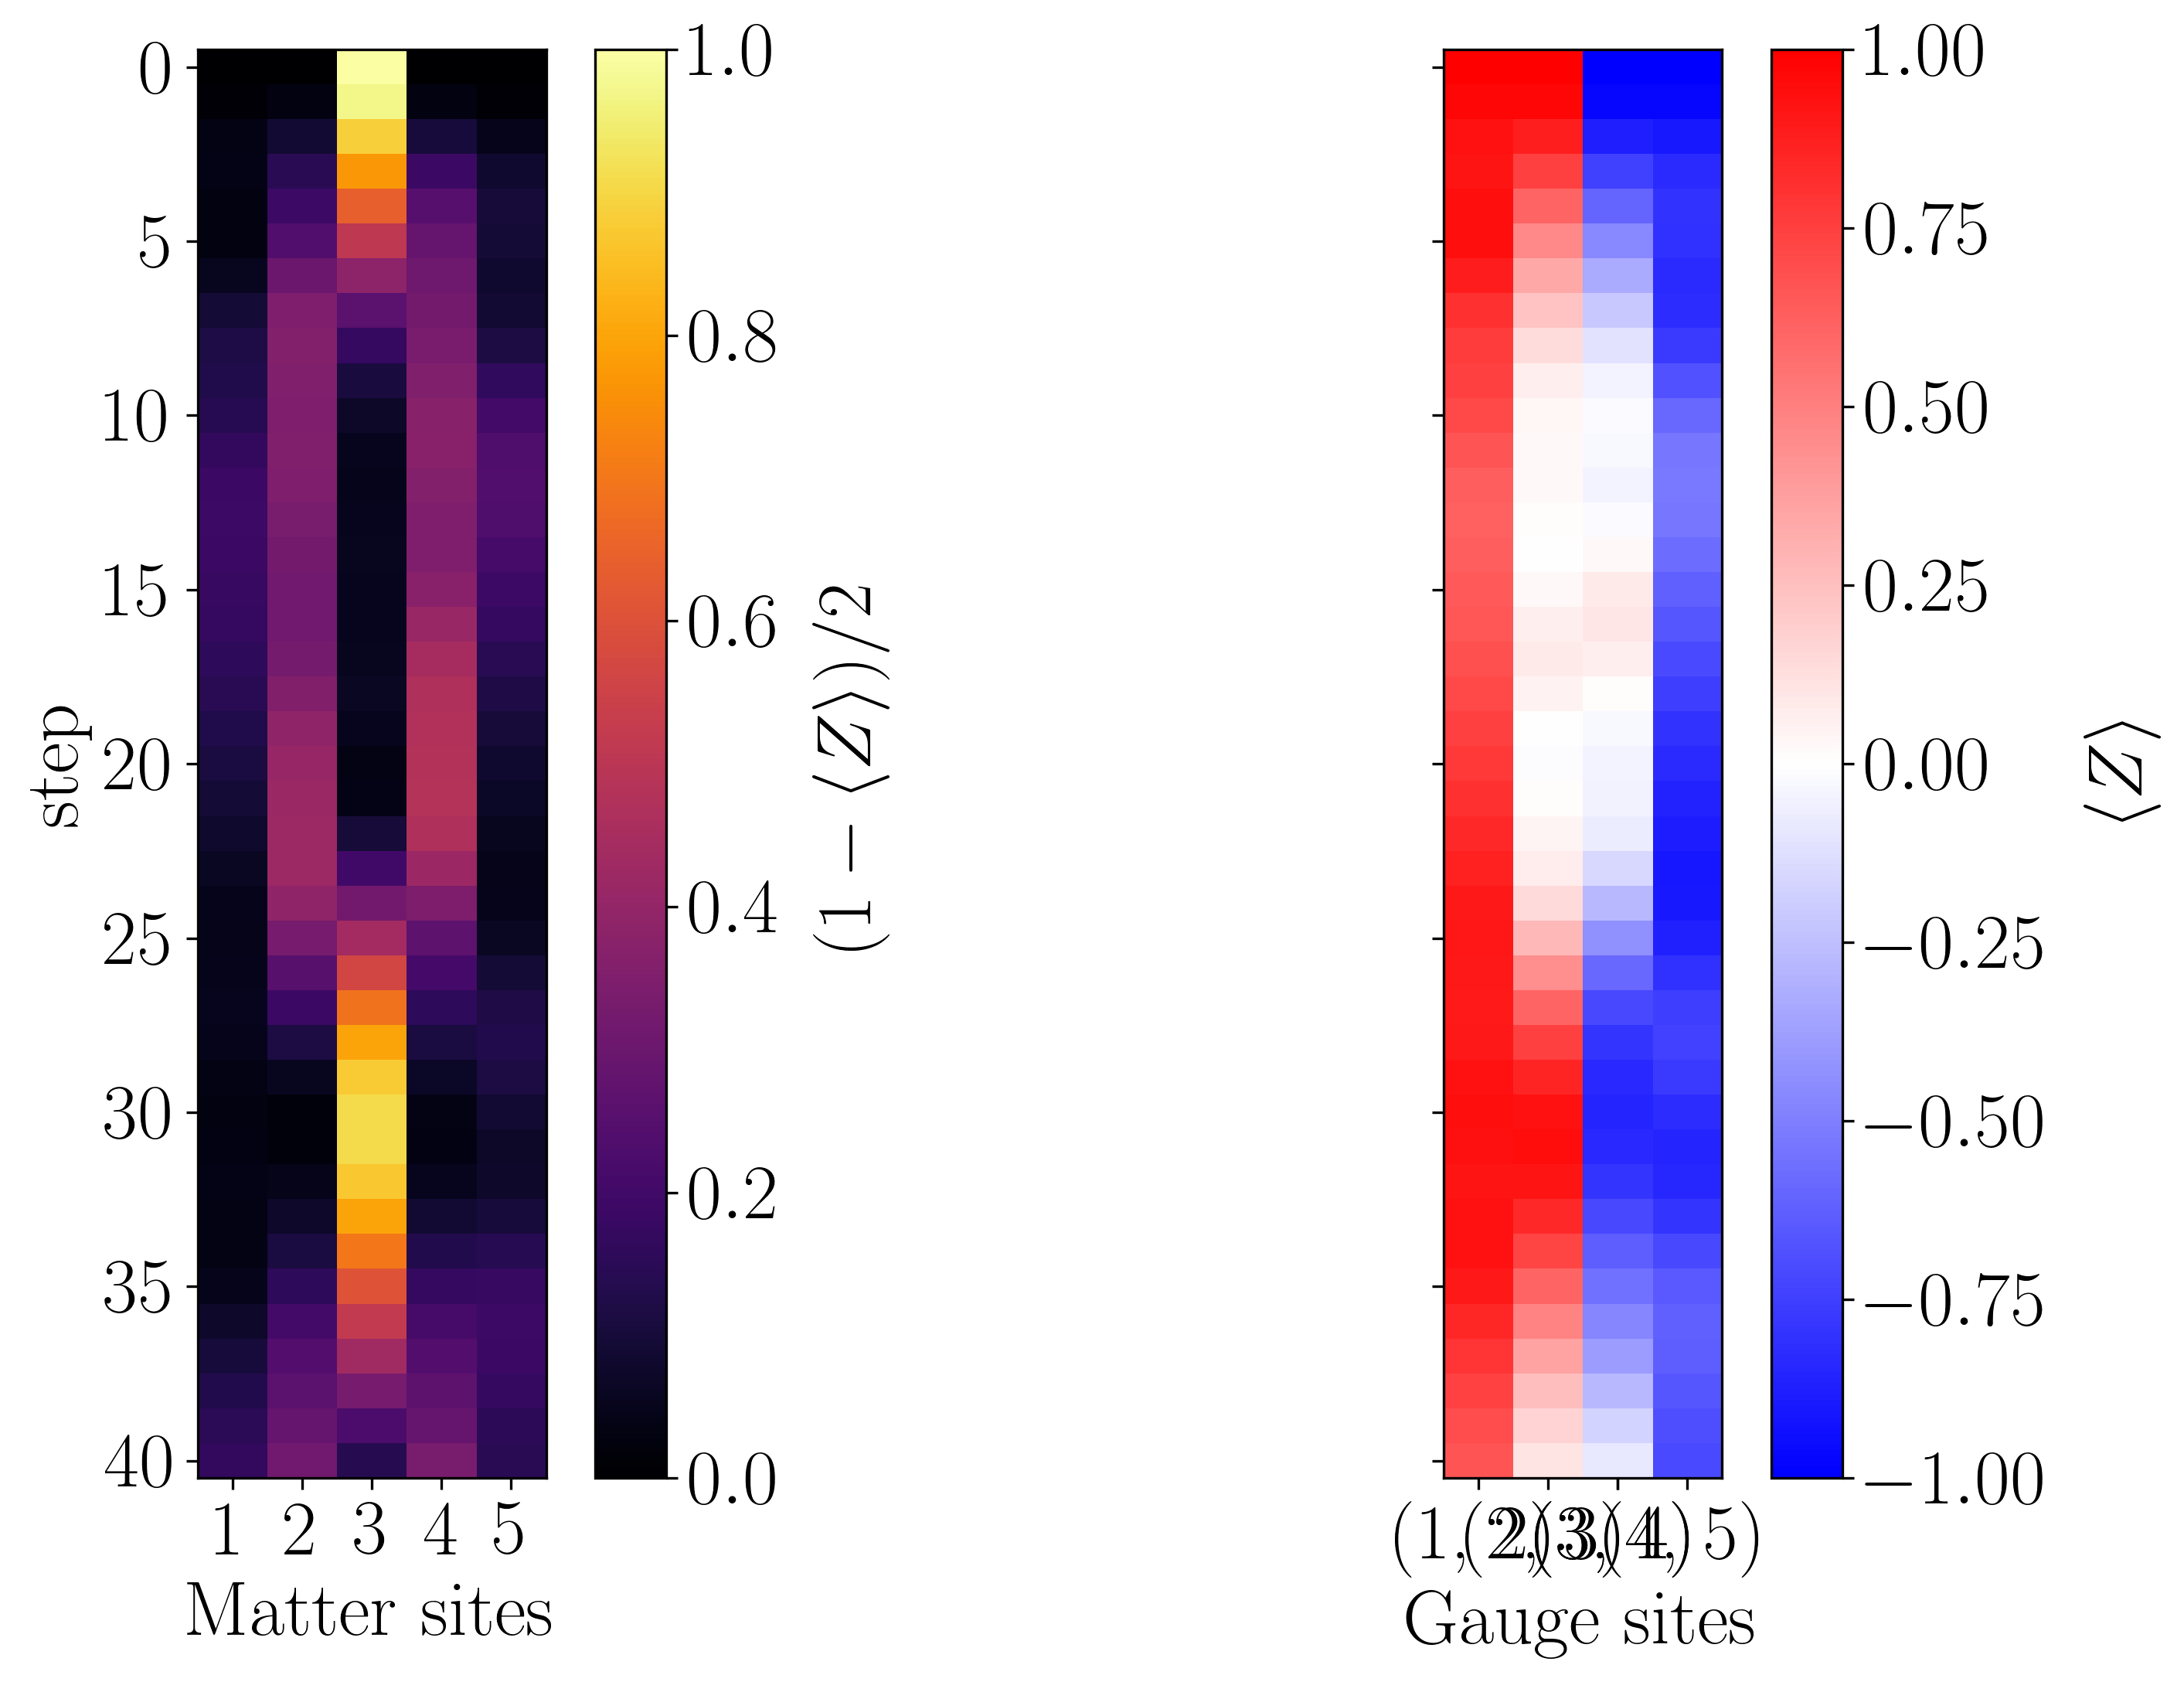

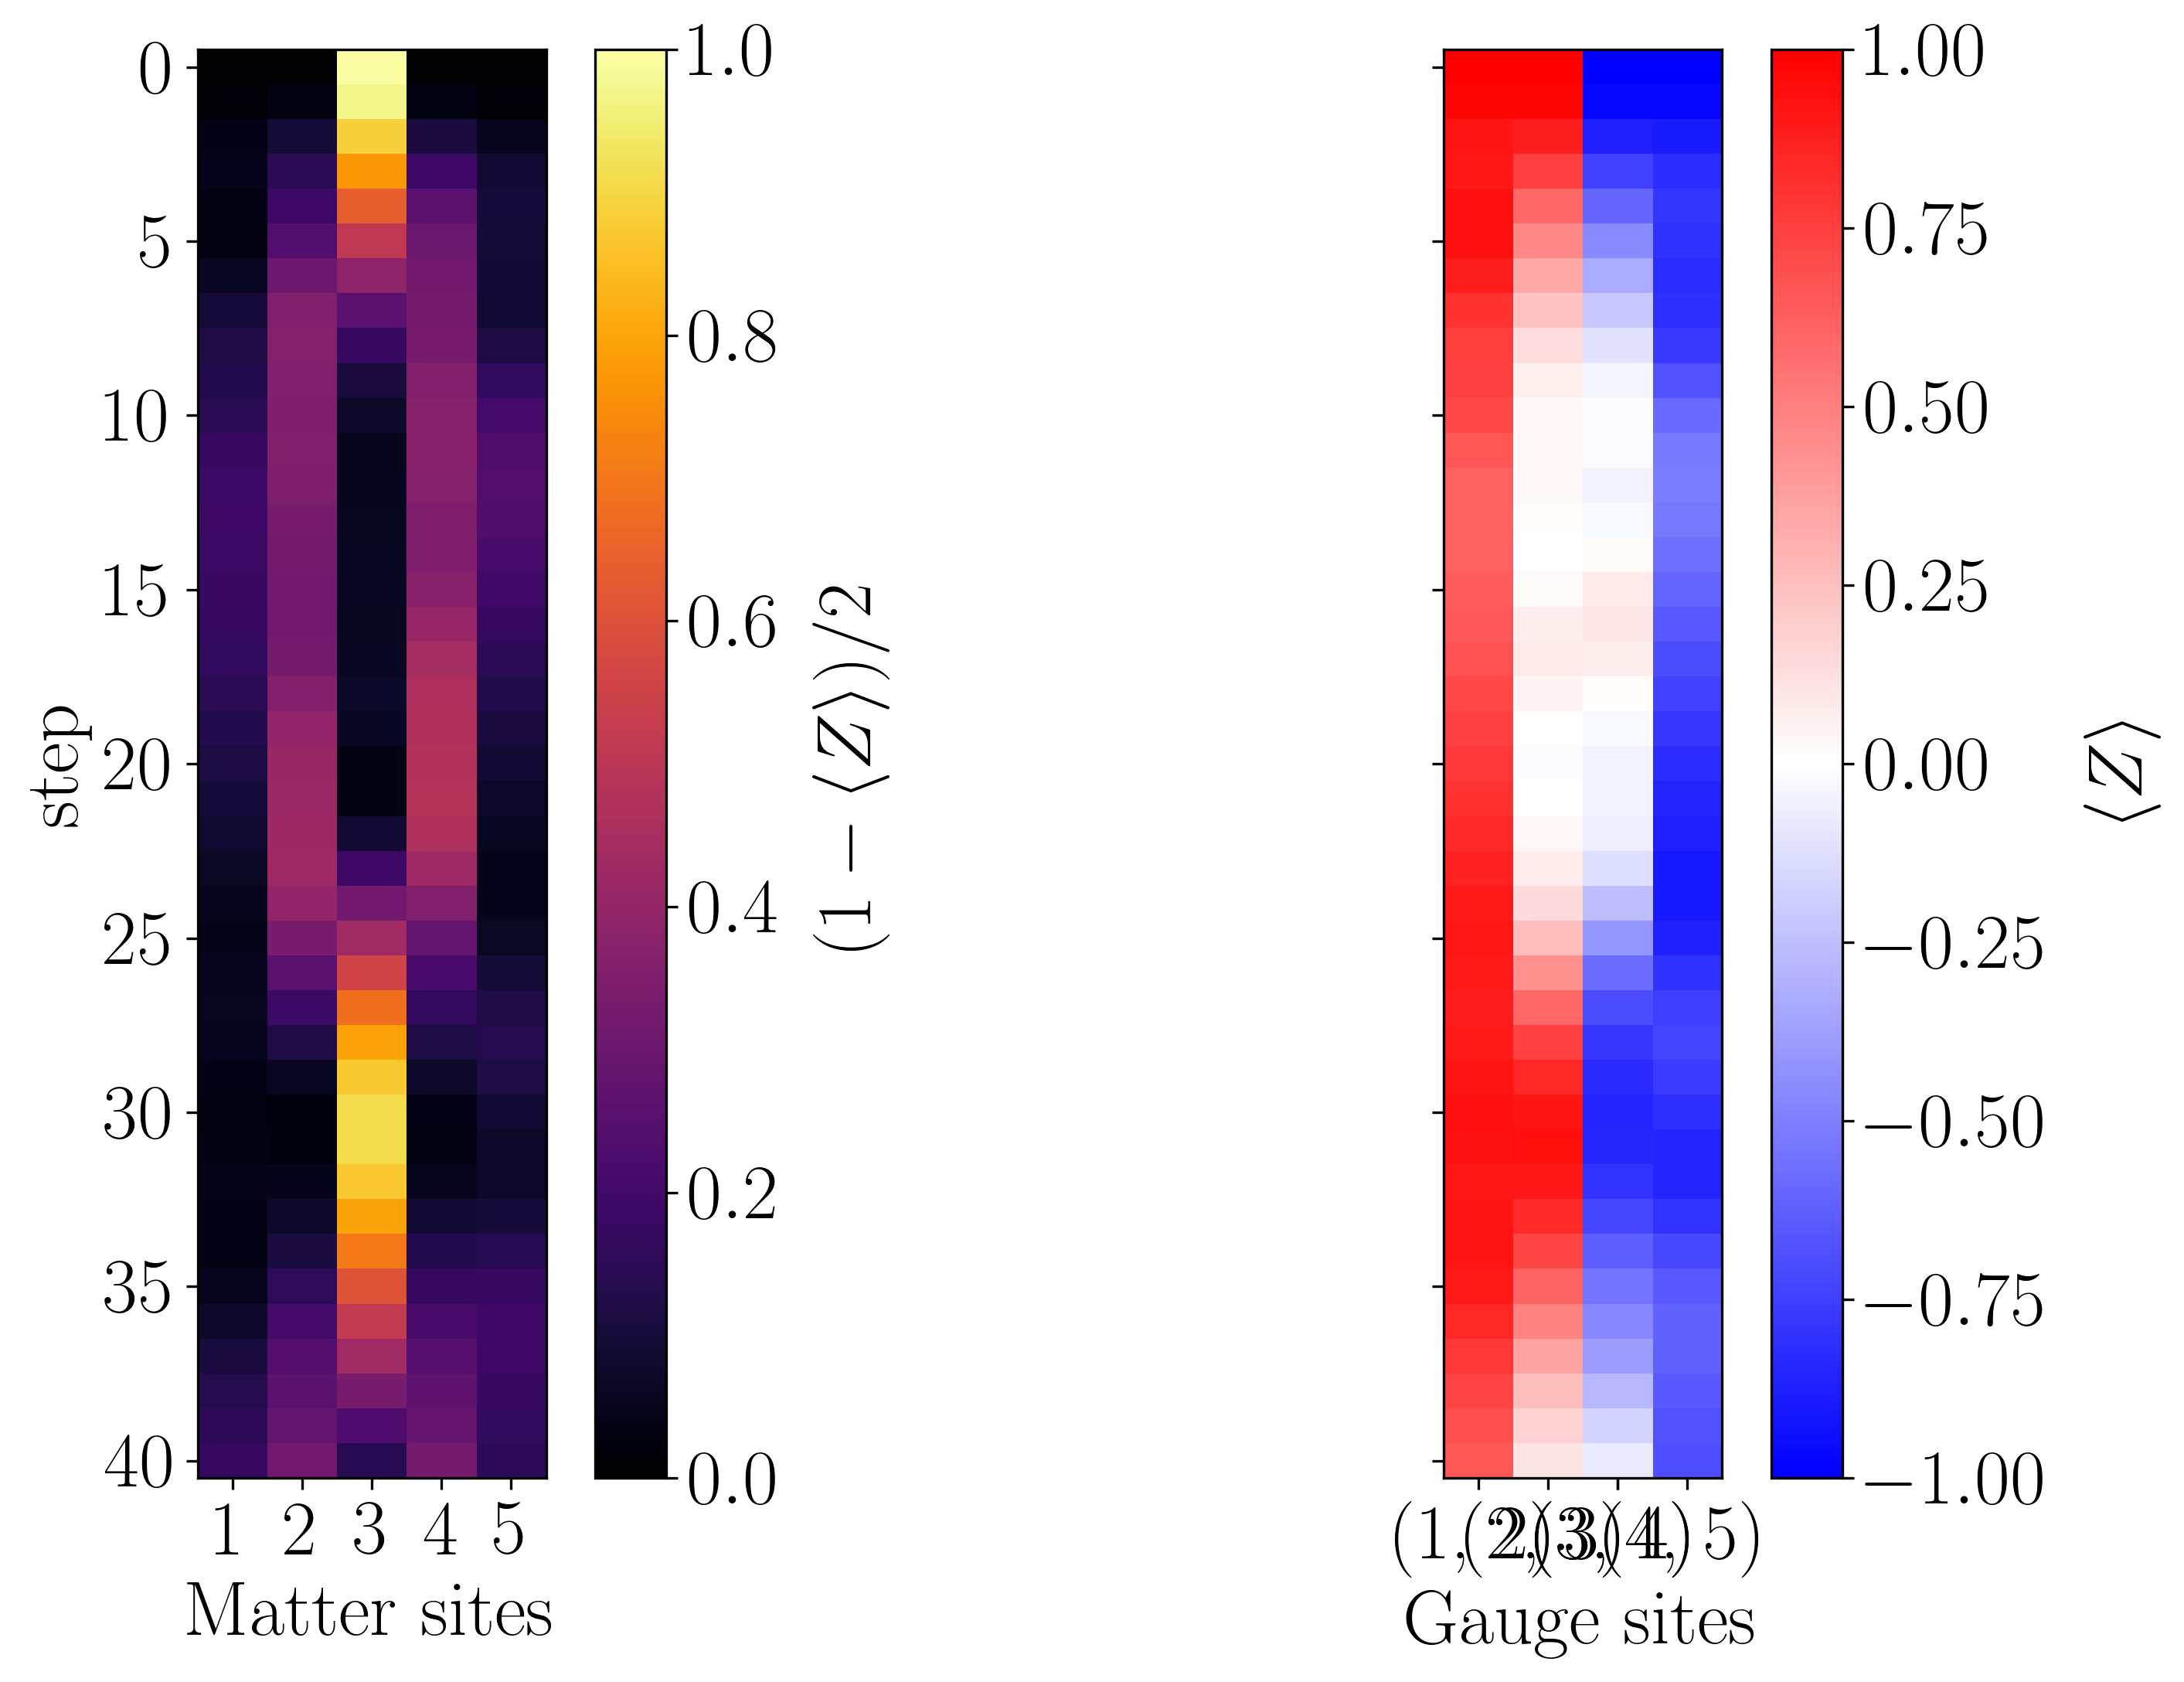

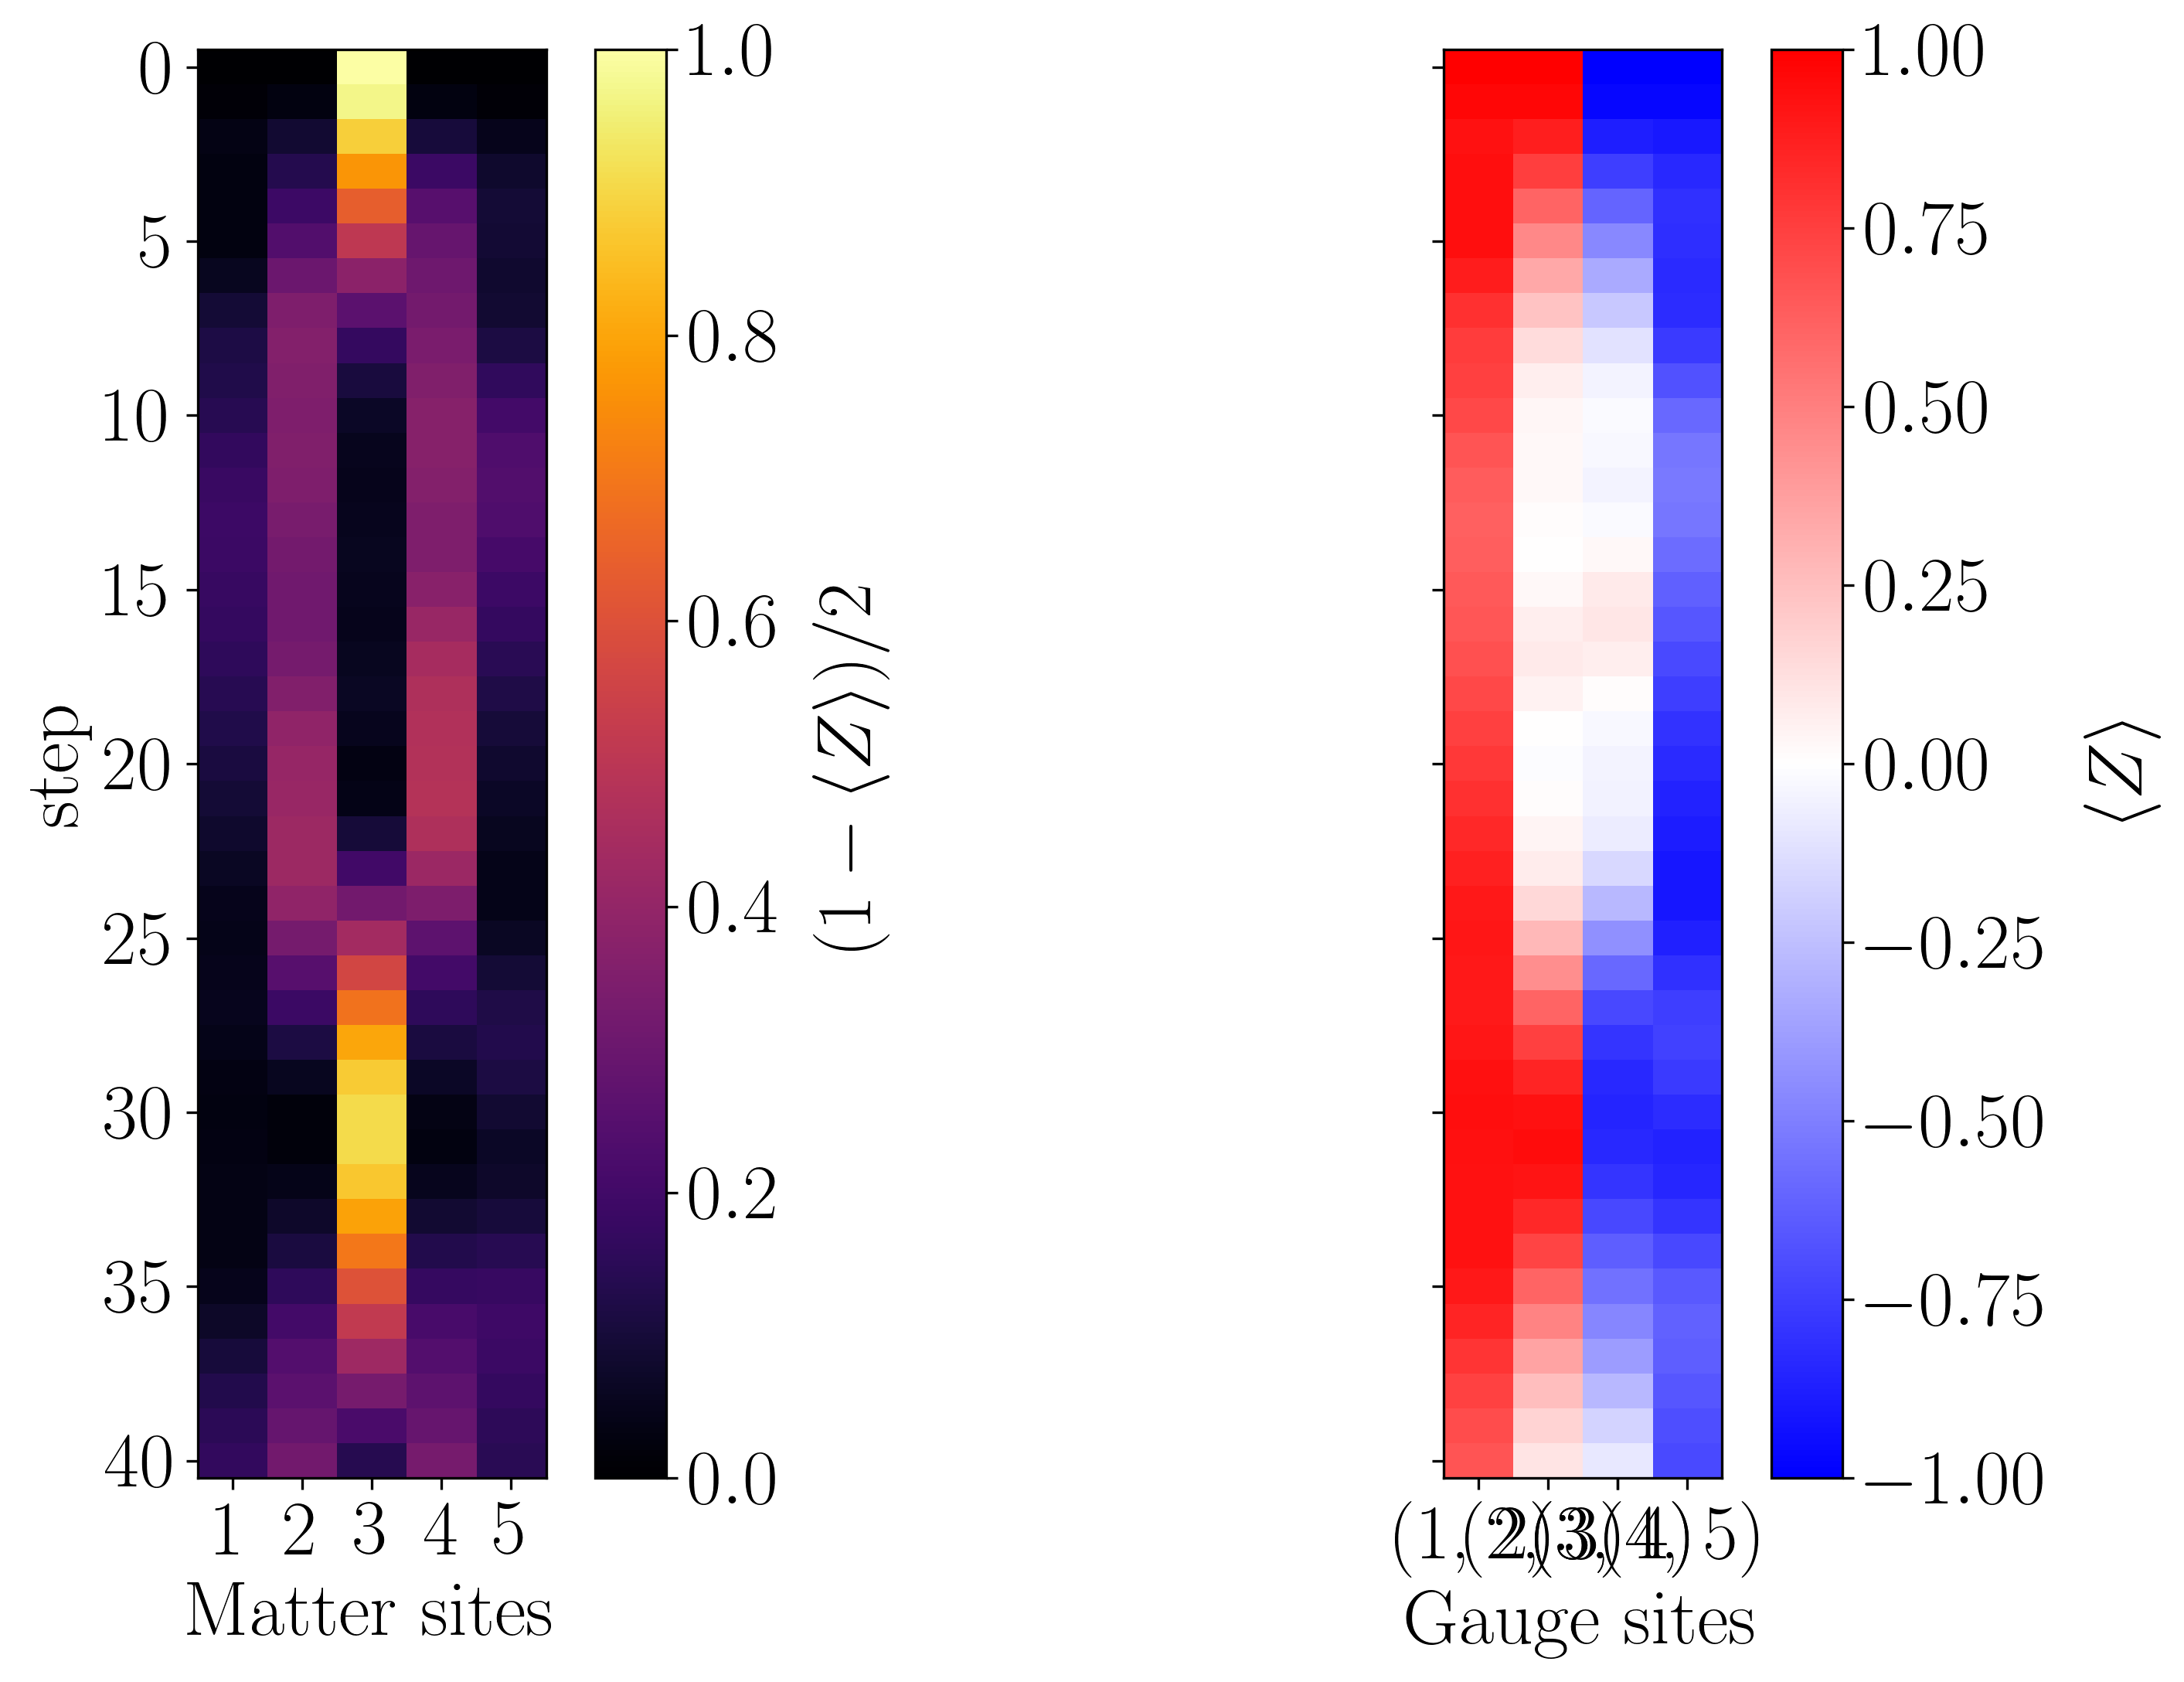

In [30]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(exact_observables)
x_t_separated_plot(t2_observables)
x_t_separated_plot(mpf2_observables)

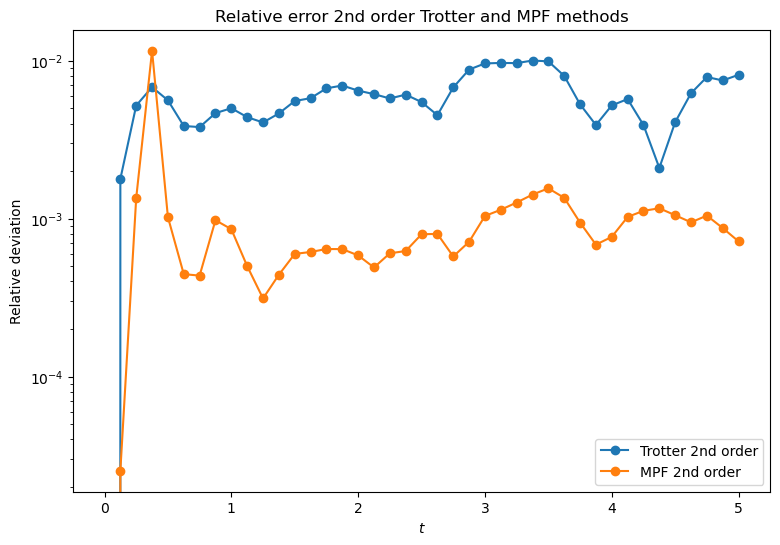

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))

t_arr = np.linspace(0, final_time, steps+1)

plt.plot(t_arr, t2_deviations, label='Trotter 2nd order', marker='o')
plt.plot(t_arr, mpf2_deviations, label='MPF 2nd order', marker='o')
plt.yscale('log')
plt.xlabel(r'$t$')
plt.ylabel('Relative deviation')
plt.title('Relative error 2nd order Trotter and MPF methods')
plt.legend()

# MPS

In [ ]:
from juliacall import Main as jl, convert as jlconvert
import juliacall

path_to_julia_tn = "../../z2chain/Z2HiggsChainDynamics.jl"
path_to_julia_mpf = "../../utils/MultiProductF.jl"
jl.seval(f"include(\"{path_to_julia_tn}\")")
jl.seval(f"include(\"{path_to_julia_mpf}\")")
jl.seval("using .Z2HiggsChainDynamics")
jl.seval("using .MultiProductF")

In [ ]:
L = 15
m = 5
g = 0.8
lamb = 1

final_time = 5

particle_pair_left_position = 4
particle_pair_length = 6

x_basis = False

## Ground truth

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

# dt = 0.14705882/20
# dt = 0.007353
dt = 0.01
steps = int(np.ceil(final_time/dt))
# comparison_increment_ct = int(dt_ct/dt)
cutoff = 1e-8

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt, steps, x_basis, False, cutoff)
    observable_matrix = np.array(observable_matrix)
    save_site_gauge_observable_matrix(observable_matrix, filepath)
else:
    observable_matrix = load_site_gauge_observable_matrix(filepath)

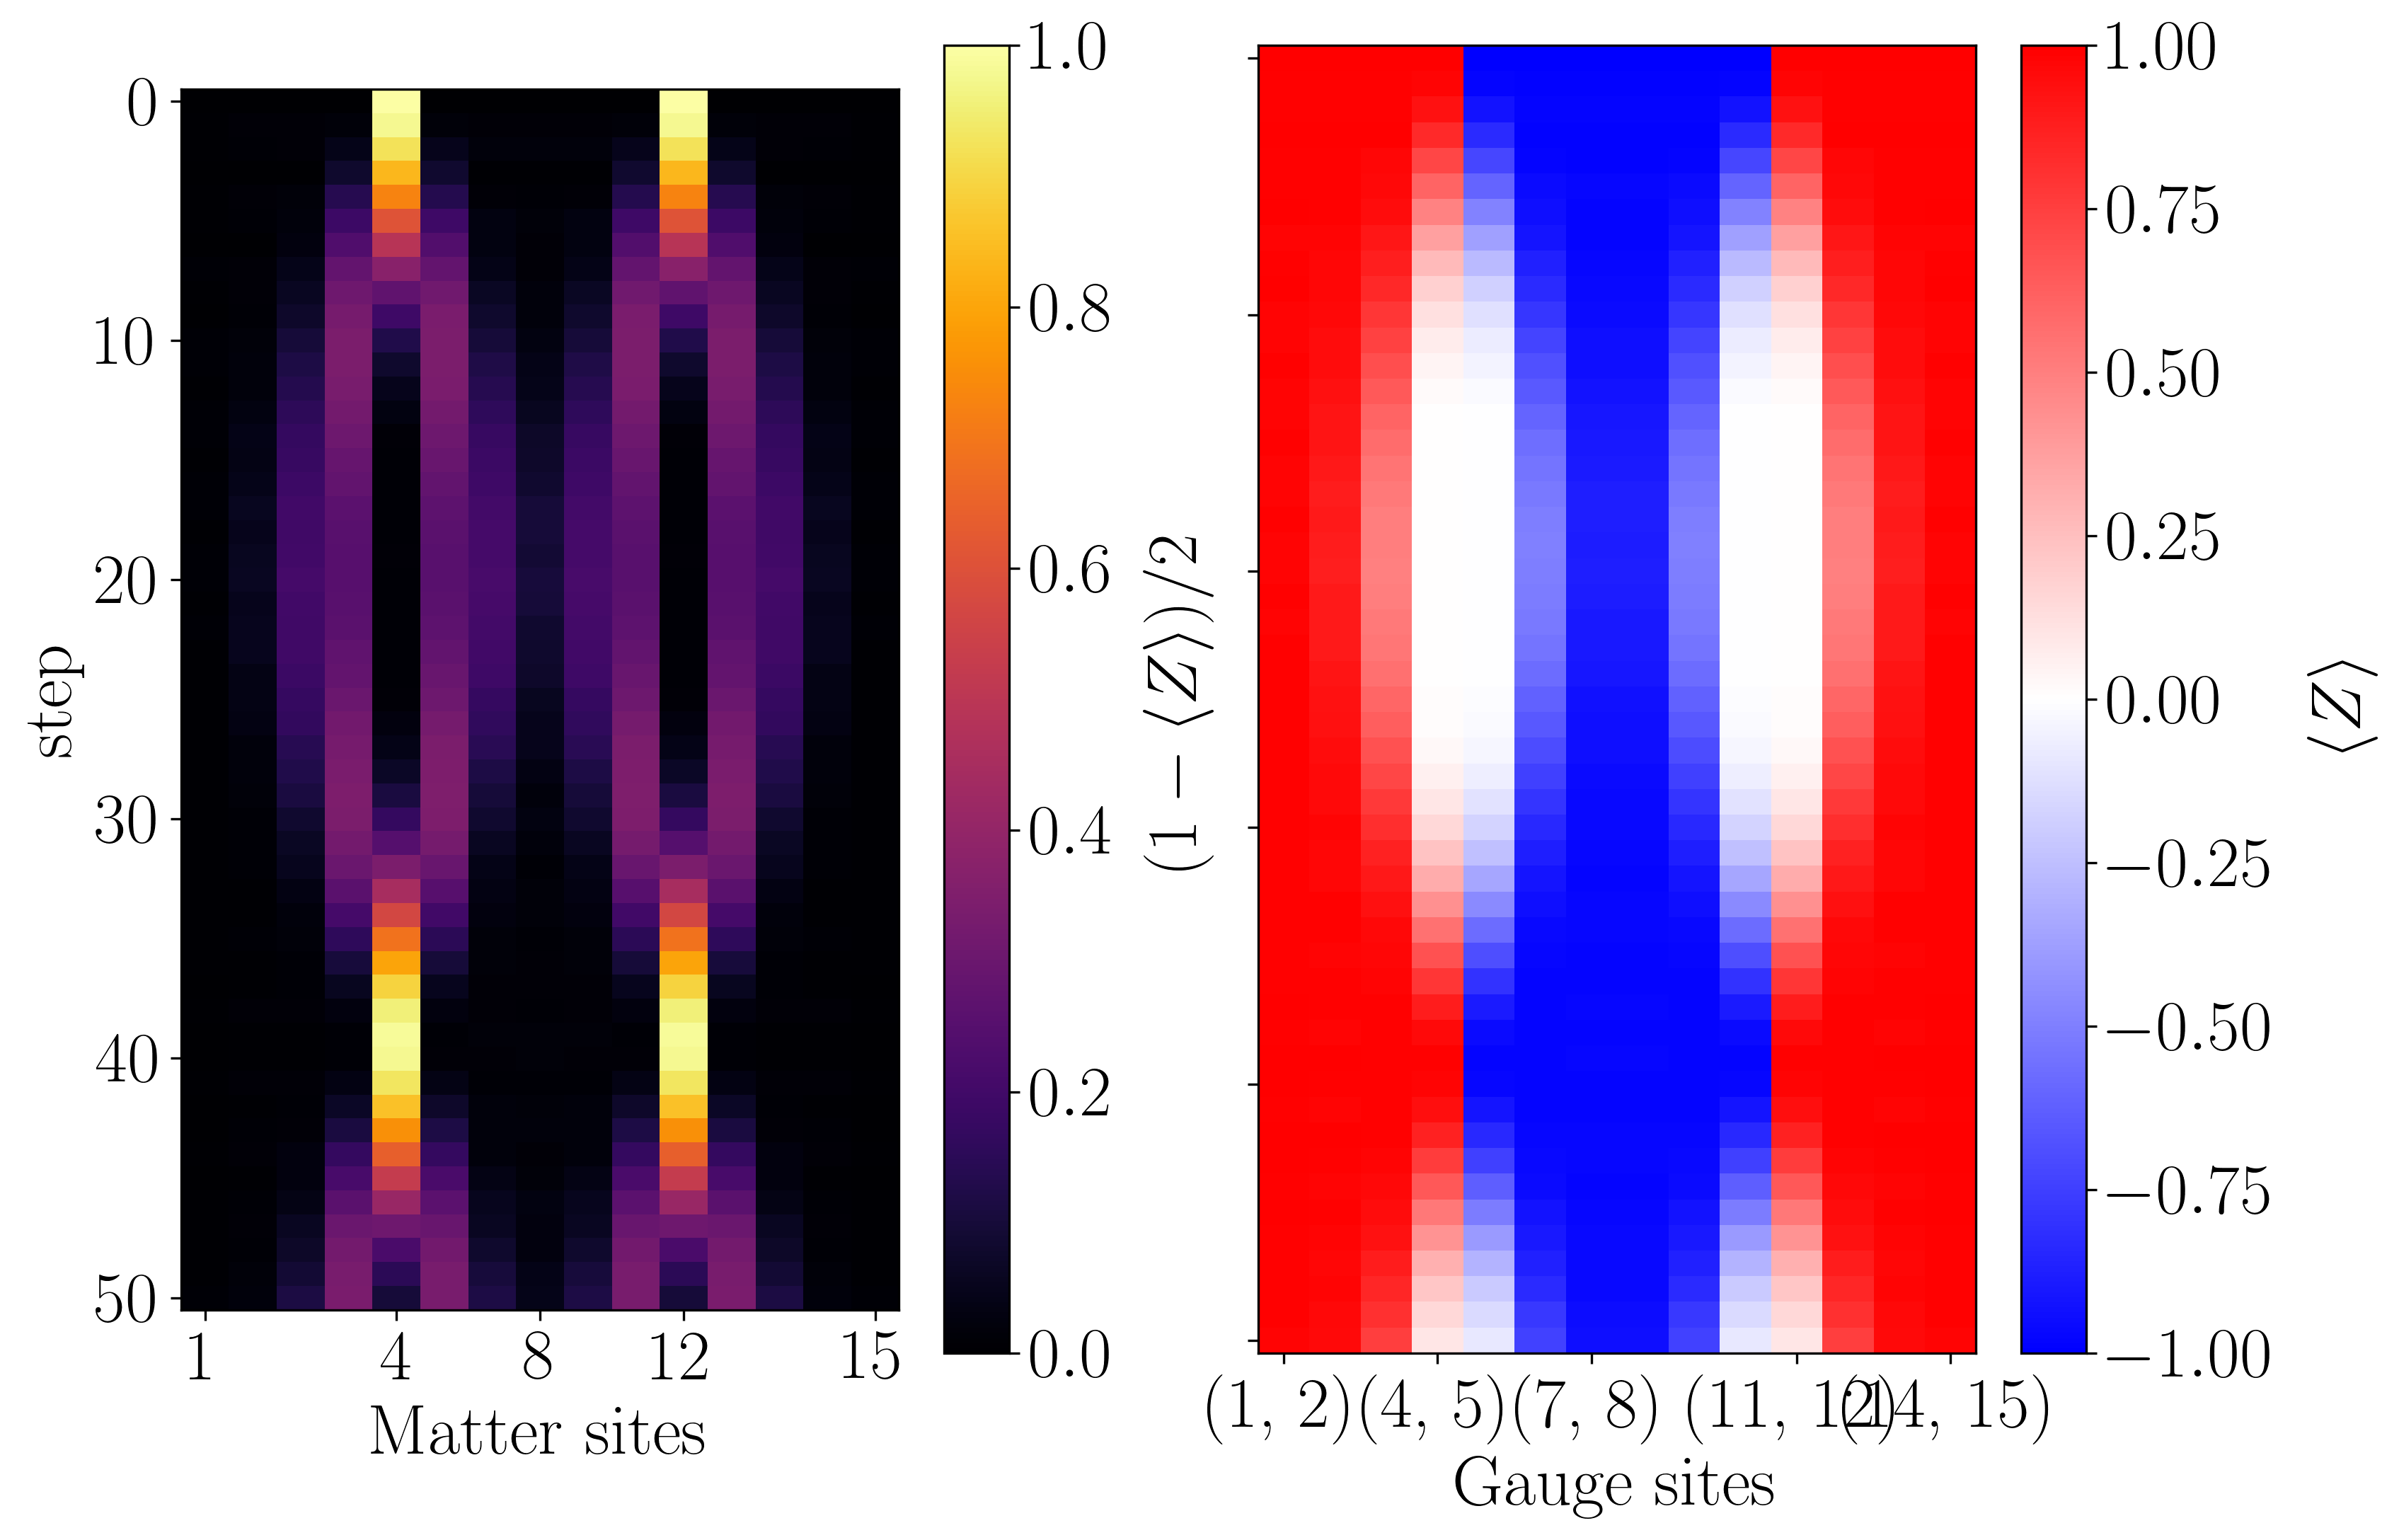

In [ ]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix[::10])

## Conventional

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_ct = 0.1
steps_ct = int(np.ceil(final_time/dt_ct))
# comparison_increment_ct = int(dt_ct/dt)
cutoff = 1e-12

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt_ct}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps_ct}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_ct = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt_ct, steps_ct, x_basis, False, cutoff)
    observable_matrix_ct = np.array(observable_matrix_ct)
    save_site_gauge_observable_matrix(observable_matrix_ct, filepath)
else:
    observable_matrix_ct = load_site_gauge_observable_matrix(filepath)

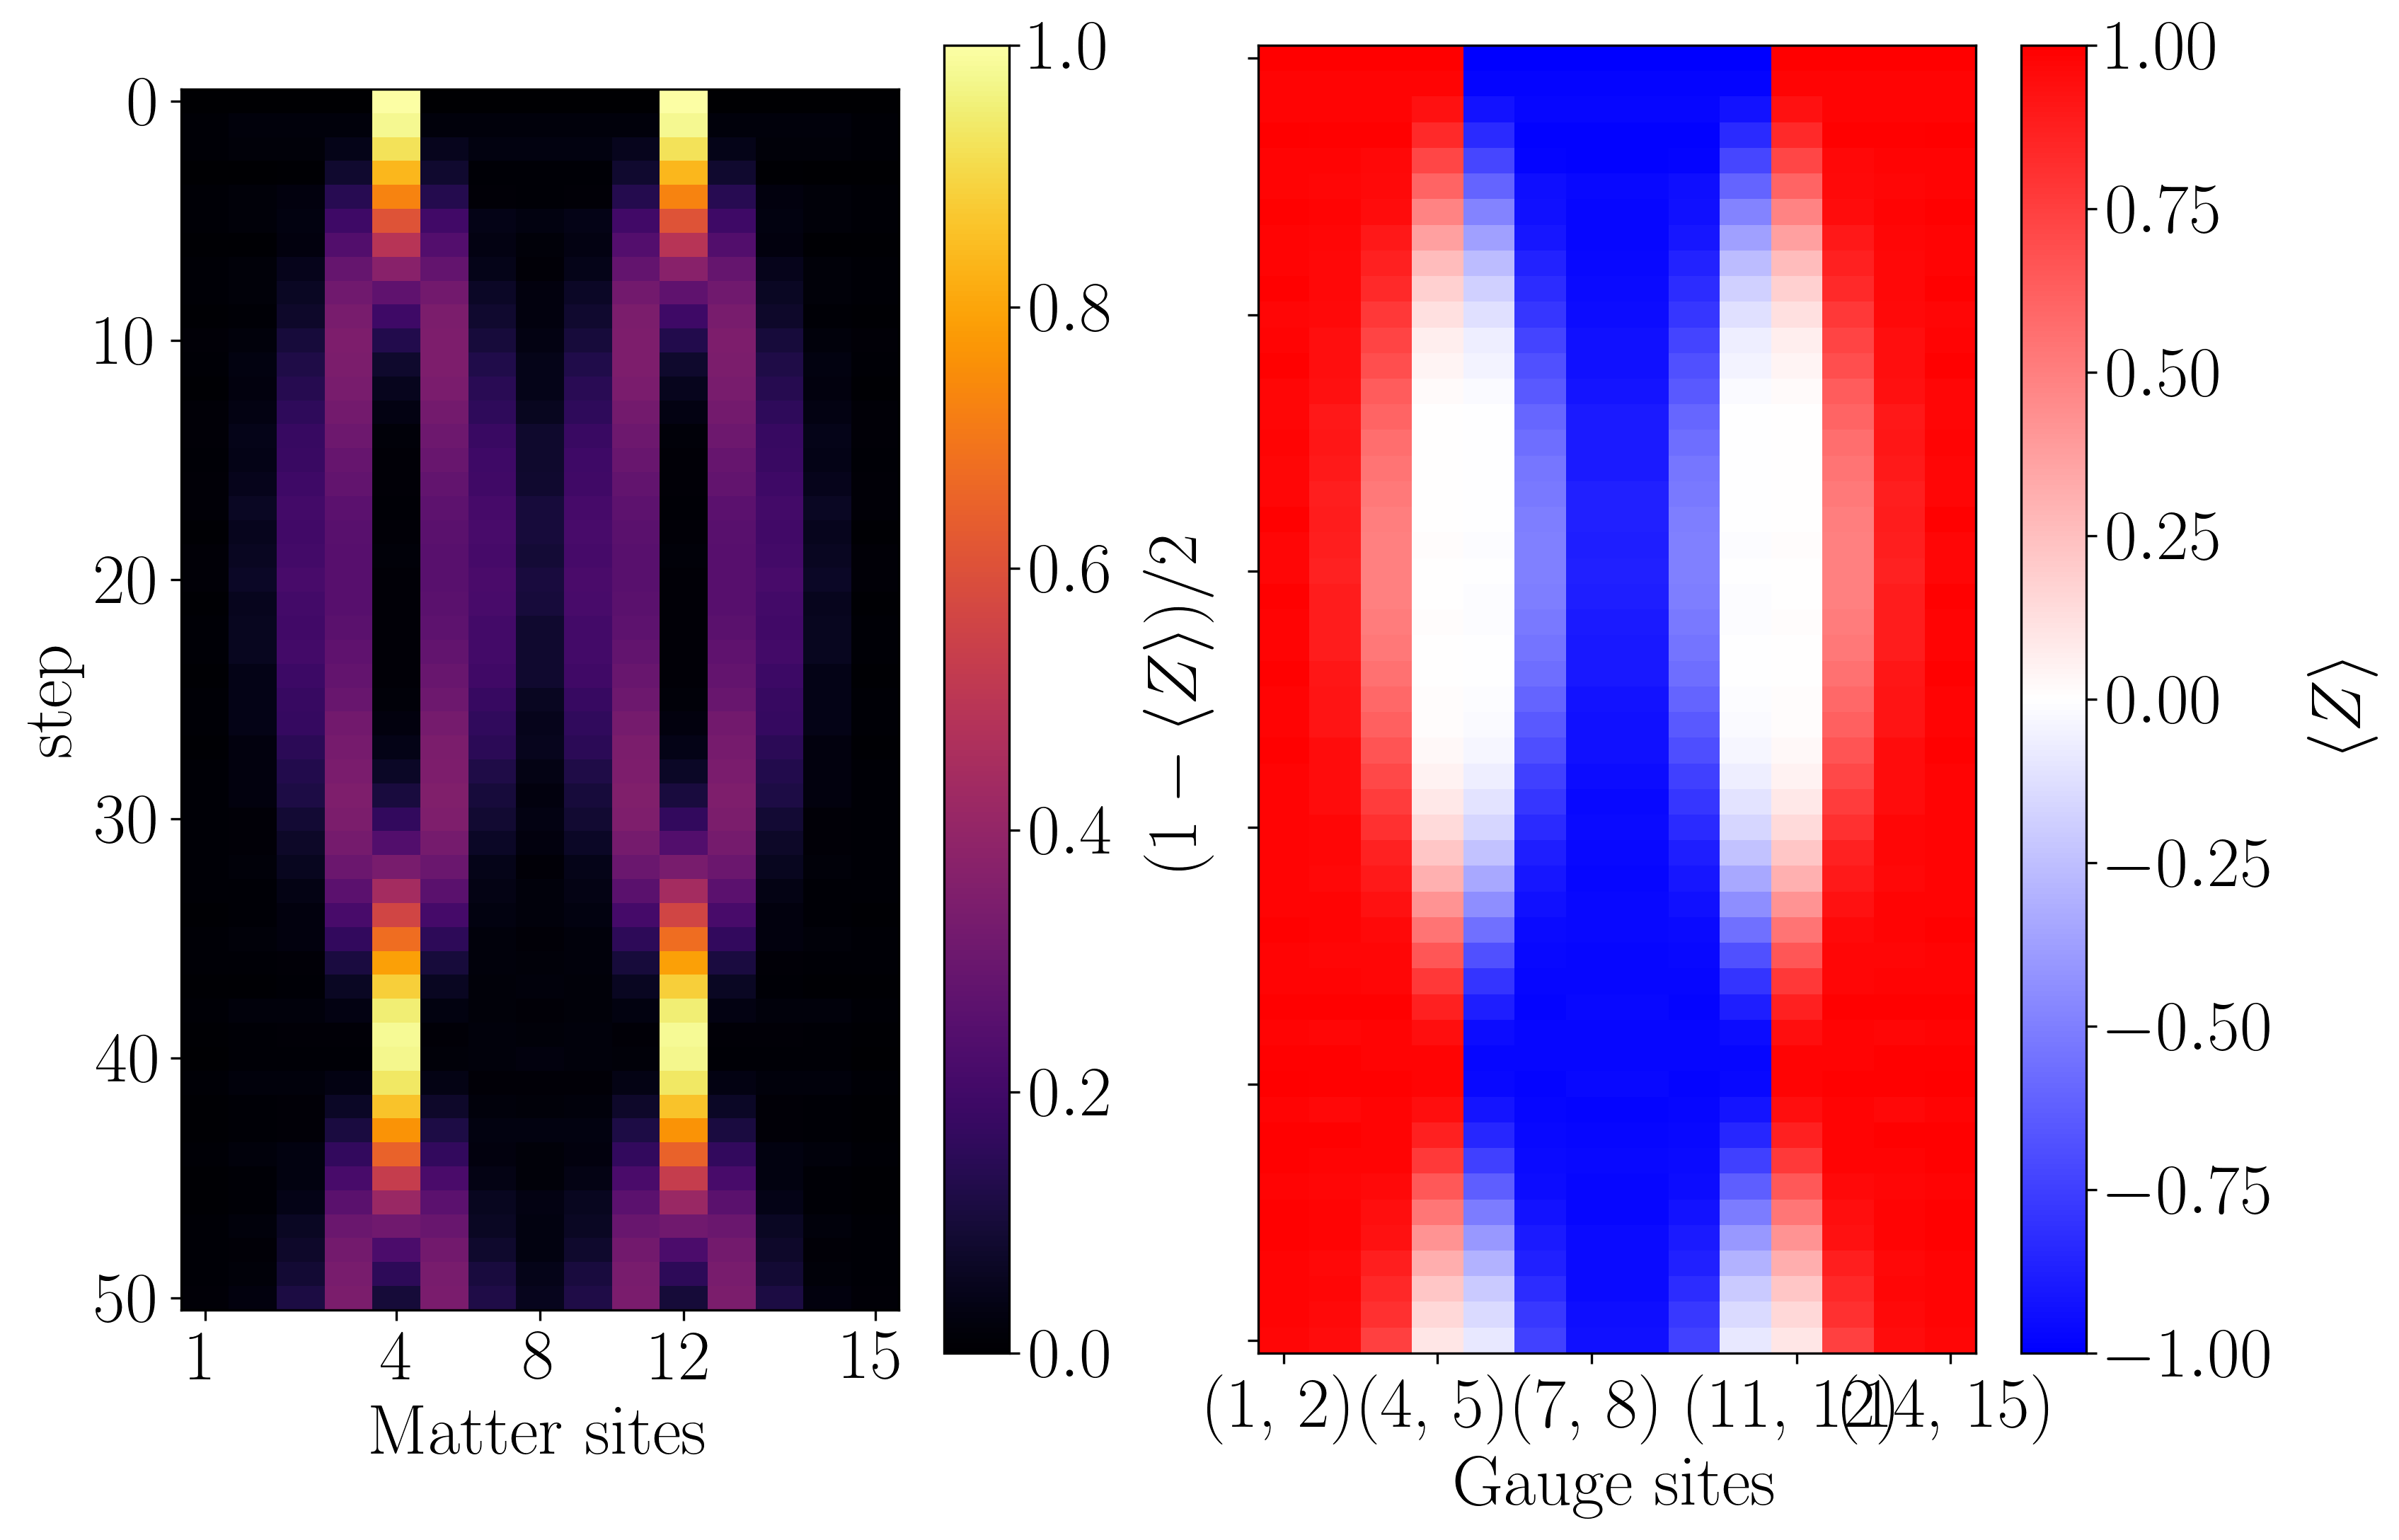

In [ ]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_ct, cbar_range_matter=[0, 1])

## Multiproduct

### TO DO properly

# Noisy

## Device selection

In [32]:
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance, group_instance2
# from fradm.tokens import ibm_token, group_instance
from qiskit_aer import AerSimulator

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

simulator = AerSimulator.from_backend(backend)
# simulator = AerSimulator()

## Simulation settings

In [57]:
from z2chain.circs import trotter_dt
from z2chain.gdd import zero_mean
import utils.multiproductf as mpf
import z2chain.exact as exact
import numpy as np

L = 5
m = 5
g = 0.8
lamb = 1

final_time = 5
# dt = trotter_dt(1e-2, L, m, g, lamb)
dt = 0.2
steps = int(np.ceil(final_time / dt))

particle_position = 2

x_basis = False

g_func = zero_mean
odr = True
flip_threshold = 4

shots = 75000
confidence = 0.7

max_anorm = 10

print(f"{steps=}")

steps=25


## Ground truth

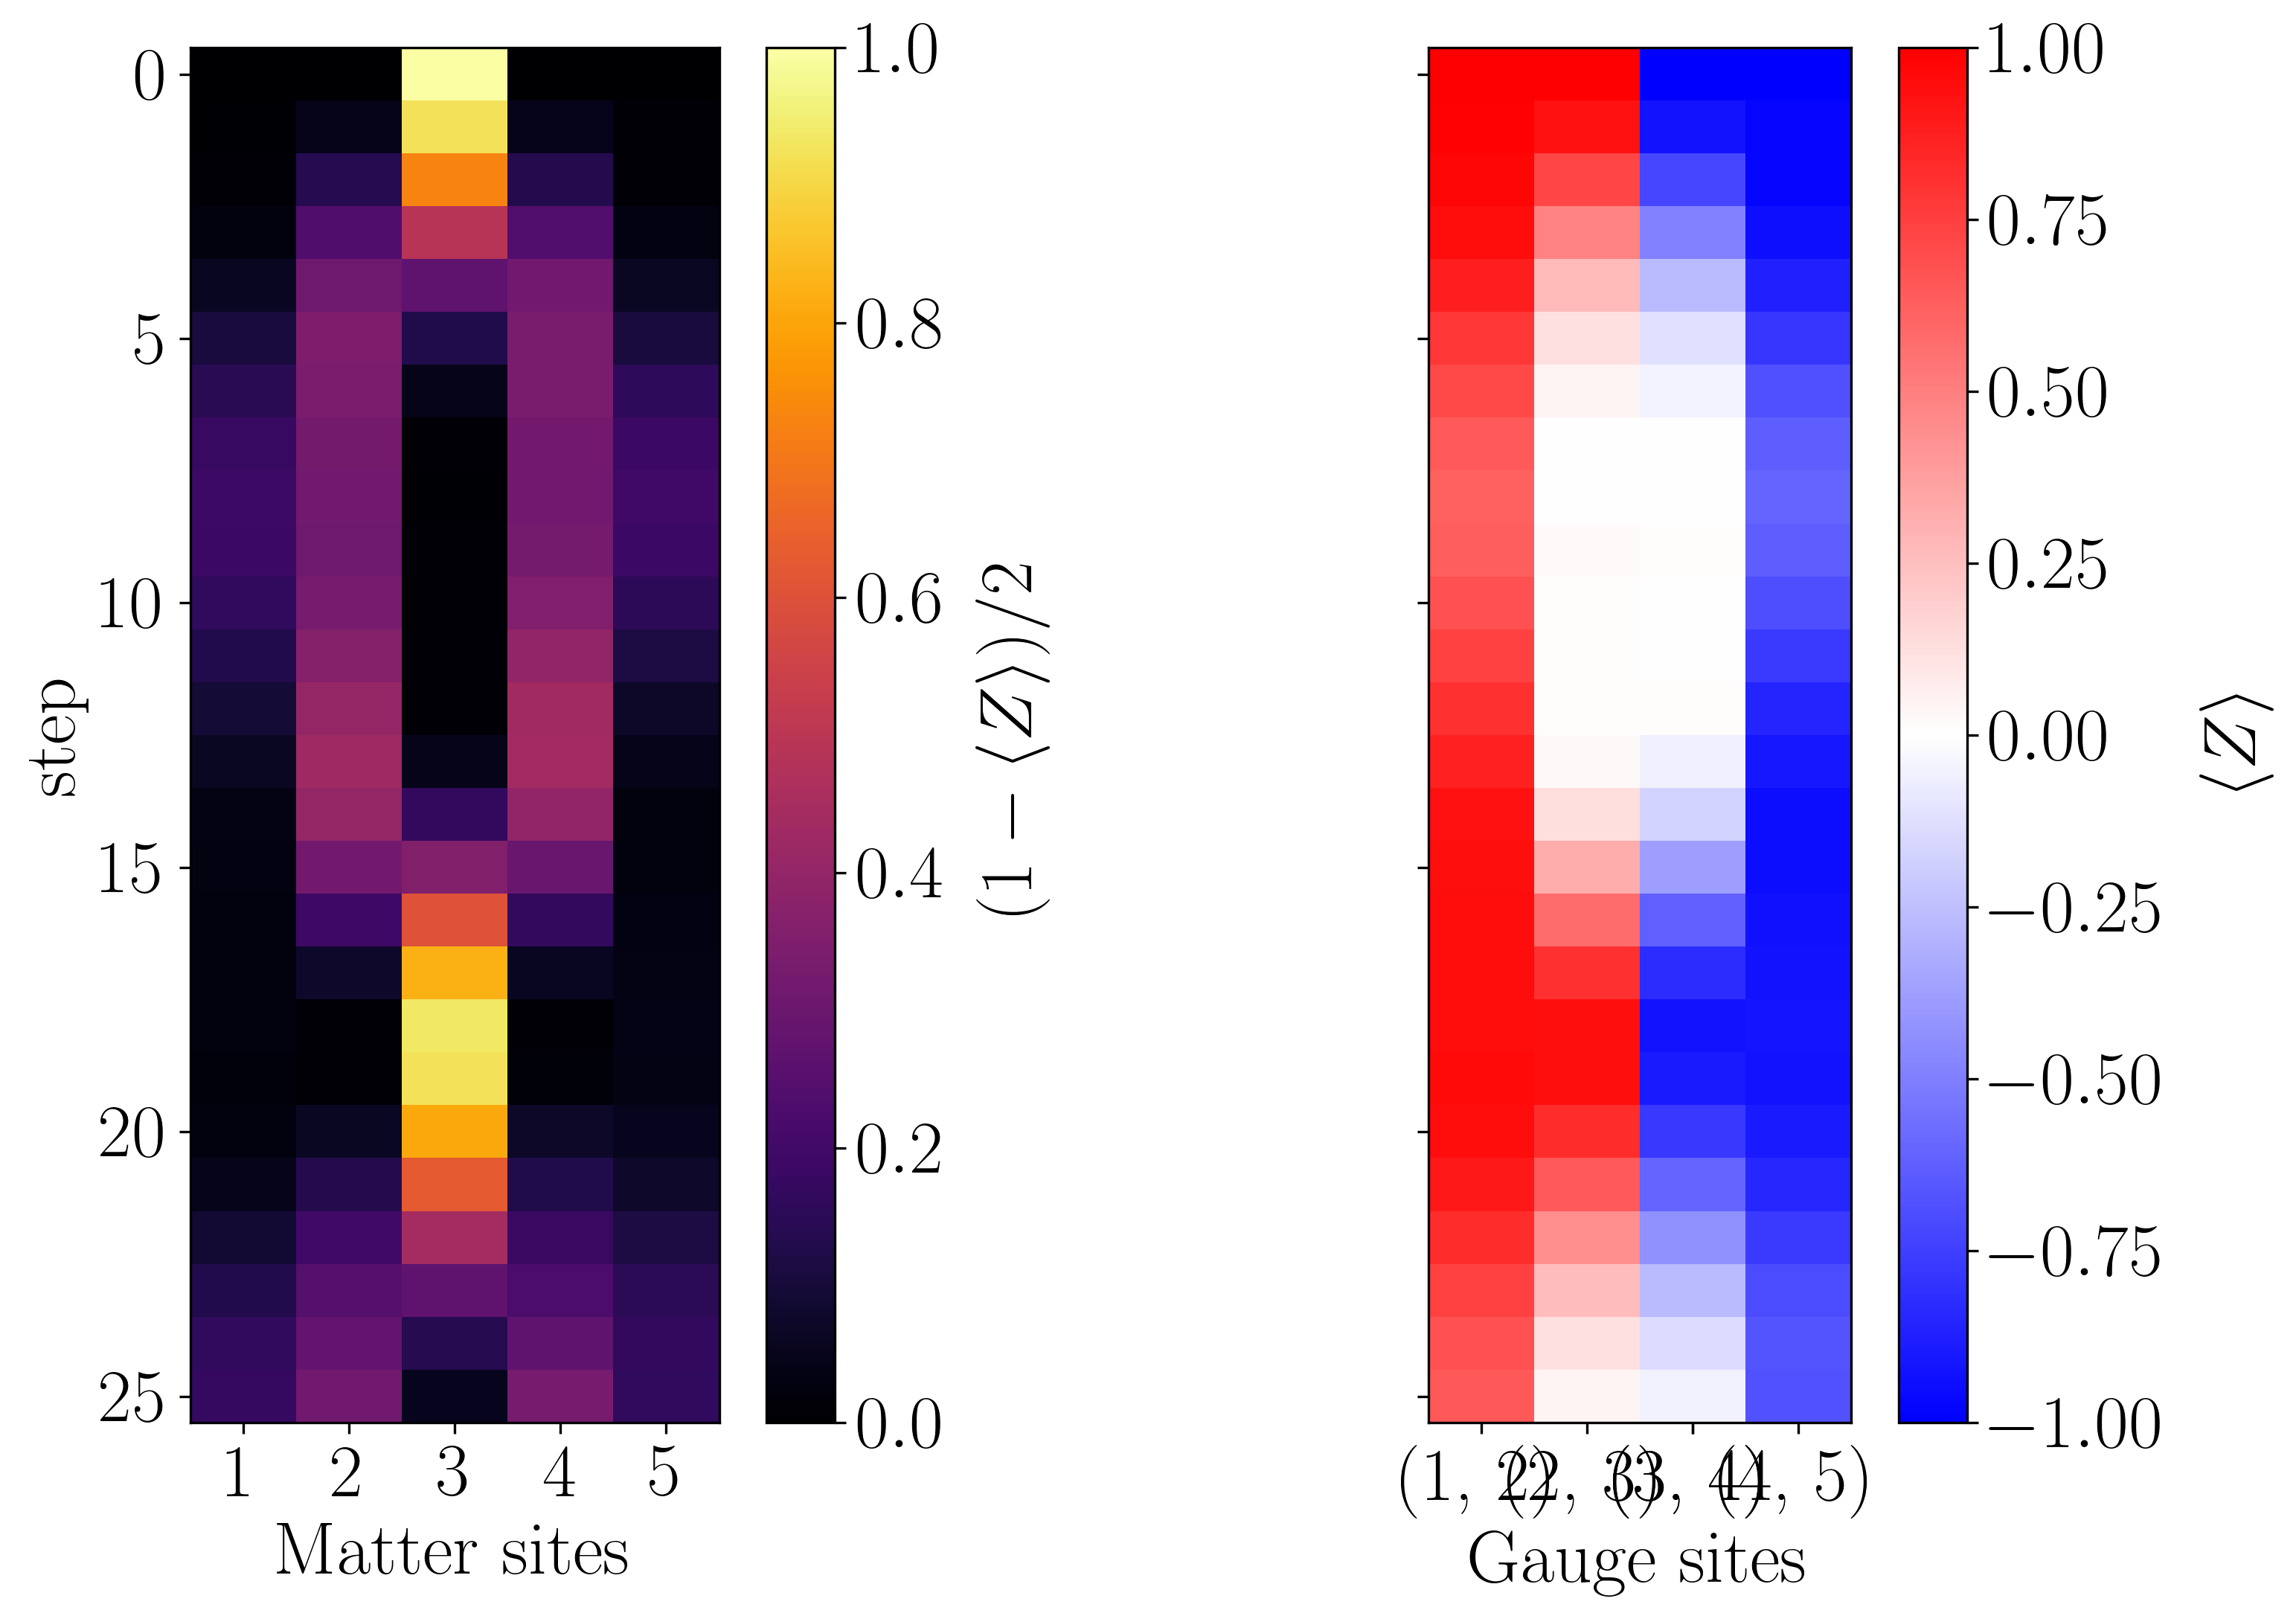

In [58]:
from z2chain.plotting import x_t_separated_plot
import z2chain.exact as exact

exact_observables = exact.singlep_quench_simulation(L, m, g, lamb, particle_position, dt, steps)

x_t_separated_plot(exact_observables)

## Error guarantees

In [59]:
from z2chain.circs import nlayers_trotter, alpha_commutator
import numpy as np

desired_precision = 1e-2

max_pf_layers = int(np.ceil(final_time / dt))
required_pf_layers = int(np.ceil(nlayers_trotter(final_time, desired_precision, L, m, g, lamb)))
original_alpha_comm = alpha_commutator(L, m, g, lamb)

ɑ_true = 102.16000000000001


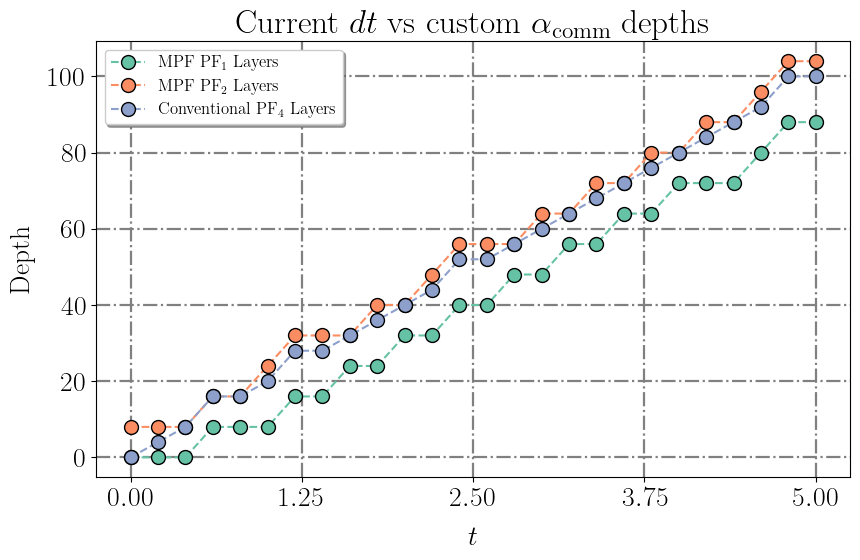

In [60]:
from z2chain.circs import alpha_commutator
import utils.multiproductf as mpf
import numpy as np

alpha_comm = float(alpha_commutator(L, m, g, lamb))
print(f"ɑ_true = {alpha_comm}")

# custom_alpha_comm = alpha_comm
custom_alpha_comm = 4

t_arr = np.linspace(0, final_time, steps+1)
# ks, coeffs = mpf.get_ks_coeffs_improvement(t_arr, custom_alpha_comm, 2, 3, 2)
ks, coeffs = mpf.get_ks_maxk_dt(t_arr, dt, 2, max_anorm, 2)

# Force even
corrected_ks = np.zeros_like(ks)
for i in range(ks.shape[1]):
    this_ks_col = ks[:, i].copy()
    if i < (corrected_ks.shape[1]-1):
        this_ks_col[~np.equal(this_ks_col % 2, 0)] -= 1
    else:
        this_ks_col[~np.equal(this_ks_col % 2, 0)] += 1
    corrected_ks[:, i] = this_ks_col

corrected_coeffs = np.zeros_like(coeffs)
for i in range(corrected_ks.shape[0]):
    if corrected_ks[i, 0] == 0:
        corrected_coeffs[i, -1] = 1
    else:
        corrected_coeffs[i] = mpf.mpfcoeffs(corrected_ks[i], 2)[0]

mpf.plt_mpf_conventional_comparison(t_arr, corrected_ks, dt, 4, x_label=r"$t$", title=r"Current $dt$ vs custom $\alpha_{\mathrm{comm}}$ depths", y_label=r"Depth")

## Circuit transpilation

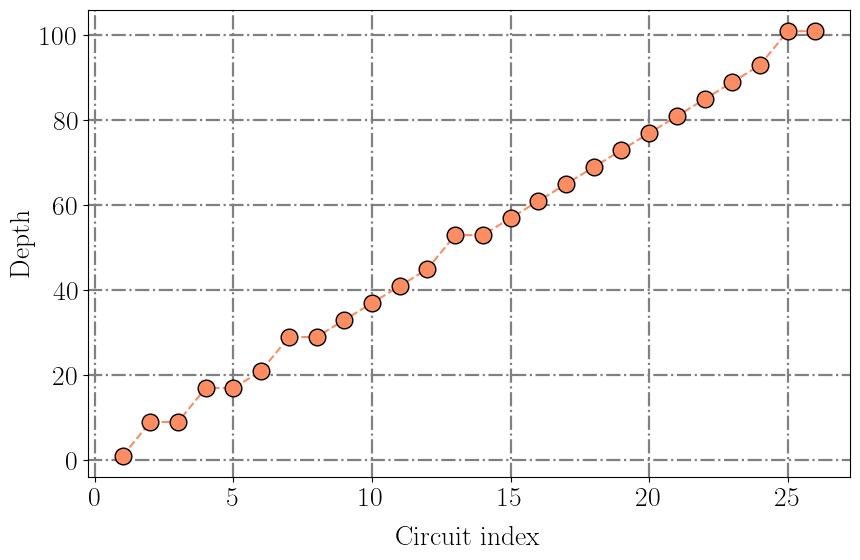

In [61]:
from z2chain.circs import singlep_quench_simulation_circuits_mpf, singlep_quench_simulation_and_odr_circs_mpf
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
from utils.circs import numpy_array_of_circuits

optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)
circs_args = (L, m, g, lamb, dt, ks[1::], backend, optimization_level, g_func, particle_position, layout, x_basis, False)
if odr:
    circuits, odr_circuits = singlep_quench_simulation_and_odr_circs_mpf(*circs_args)
else:
    circuits = singlep_quench_simulation_circuits_mpf(*circs_args)

circuits = numpy_array_of_circuits(circuits)
odr_circuits = numpy_array_of_circuits(odr_circuits)

observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)
plot_circuit_arr_depth(circuits[:, 1])

## Simulation

In [62]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from utils.odr import renormalize_observable
import numpy as np

print("\rRunning simulation...".ljust(100), end="")
samples_dicts = np.full(ks.shape, {}, dtype=object)
if odr: odr_samples_dicts = np.full(ks.shape, {}, dtype=object)
for i, this_t_ks in enumerate(ks):
    this_t_samples_dicts = np.full(ks.shape[1], {}, dtype=object)
    for j, k in enumerate(this_t_ks):
        this_t_samples_dicts[j] = simulator.run(circuits[i][j], shots=shots).result().get_counts()
    samples_dicts[i] = this_t_samples_dicts
    if odr:
        this_t_odr_samples_dicts = np.full(ks.shape[1], {}, dtype=object)
        for j, k in enumerate(this_t_ks):
            this_t_odr_samples_dicts[j] = simulator.run(odr_circuits[i][j], shots=shots).result().get_counts()
        odr_samples_dicts[i] = this_t_odr_samples_dicts

print("\rMeasuring observables...".ljust(100), end="")
postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts.flatten(), postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
postselected_samples_dicts.reshape(samples_dicts.shape)
if odr:
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(odr_samples_dicts.flatten(), postselection_ops, flip_threshold, recovery_function=None)
    postselected_odr_samples_dicts.reshape(odr_samples_dicts.shape)

sim_observables_mpf, sim_observables_confidence_mpf = multiprocess_measure_diagonal_observables(postselected_samples_dicts.flatten(), diagonal_observables, 0 if confidence is None else confidence)
sim_observables_mpf = sim_observables_mpf.reshape((*samples_dicts.shape, -1))
sim_observables_confidence_mpf = sim_observables_confidence_mpf.reshape((*samples_dicts.shape, -1))
raw_observables_mpf, raw_observables_confidence_mpf = multiprocess_measure_diagonal_observables(samples_dicts.flatten(), diagonal_observables, 0 if confidence is None else confidence)
raw_observables_mpf = raw_observables_mpf.reshape((*samples_dicts.shape, -1))
raw_observables_confidence_mpf = raw_observables_confidence_mpf.reshape((*samples_dicts.shape, -1))
if odr:
    odr_observables_mpf, odr_observables_confidence_mpf = multiprocess_measure_diagonal_observables(postselected_odr_samples_dicts.flatten(), diagonal_observables, 0 if confidence is None else confidence)
    odr_observables_mpf = odr_observables_mpf.reshape((*odr_samples_dicts.shape, -1))
    odr_observables_confidence_mpf = odr_observables_confidence_mpf.reshape((*odr_samples_dicts.shape, -1))
    clean_observables_mpf = np.zeros_like(sim_observables_mpf)
    clean_observables_confidence_mpf = np.zeros_like(sim_observables_confidence_mpf)
    # for i in range(sim_observables_mpf.shape[0]):
    #     for j in range(sim_observables_mpf.shape[1]):
    #         p_arr = compute_depolarizing_probability(odr_observables_mpf[i, j], 1, 0, odr_circuits[i, j].num_qubits)
    #         clean_observables_mpf[i, j], clean_observables_confidence_mpf[i, j] = renormalize_observable(sim_observables_mpf[i, j], p_arr, 0, circuits[i][j].num_qubits, observable_range=(-1, 1), expected_observable_arr=1, observable_confidence=sim_observables_confidence_mpf[i, j])
    for i in range(sim_observables_mpf.shape[1]):
        p_arr = compute_depolarizing_probability(odr_observables_mpf[:, i, :], 1, 0, odr_circuits[0, i].num_qubits)
        clean_observables_mpf[:, i, :] = renormalize_observable(sim_observables_mpf[:, i, :], p_arr, 0, circuits[0, i].num_qubits, observable_range=(-1, 1), expected_observable_arr=1, observable_confidence=None)

sim_observables = np.zeros((ks.shape[0], len(observable_generating_funcs)))
sim_observables_confidence = np.zeros_like(sim_observables)
raw_observables = np.zeros_like(sim_observables)
raw_observables_confidence = np.zeros_like(sim_observables)
if odr:
    odr_observables = np.zeros_like(sim_observables)
    odr_observables_confidence = np.zeros_like(sim_observables)
    clean_observables = np.zeros_like(sim_observables)
    clean_observables_confidence = np.zeros_like(sim_observables)

for i in range(sim_observables.shape[0]):
    sim_observables[i] = np.sum(sim_observables_mpf[i, :, :] * coeffs[i, :].reshape((-1, 1)), axis=0)
    raw_observables[i] = np.sum(raw_observables_mpf[i, :, :] * coeffs[i, :].reshape((-1, 1)), axis=0)
    if odr:
        odr_observables[i] = np.sum(odr_observables_mpf[i, :, :] * coeffs[i, :].reshape((-1, 1)), axis=0)
        clean_observables[i] = np.sum(clean_observables_mpf[i, :, :] * coeffs[i, :].reshape((-1, 1)), axis=0)
    # TODO: Implement confidences

Measuring observables...                                                                           

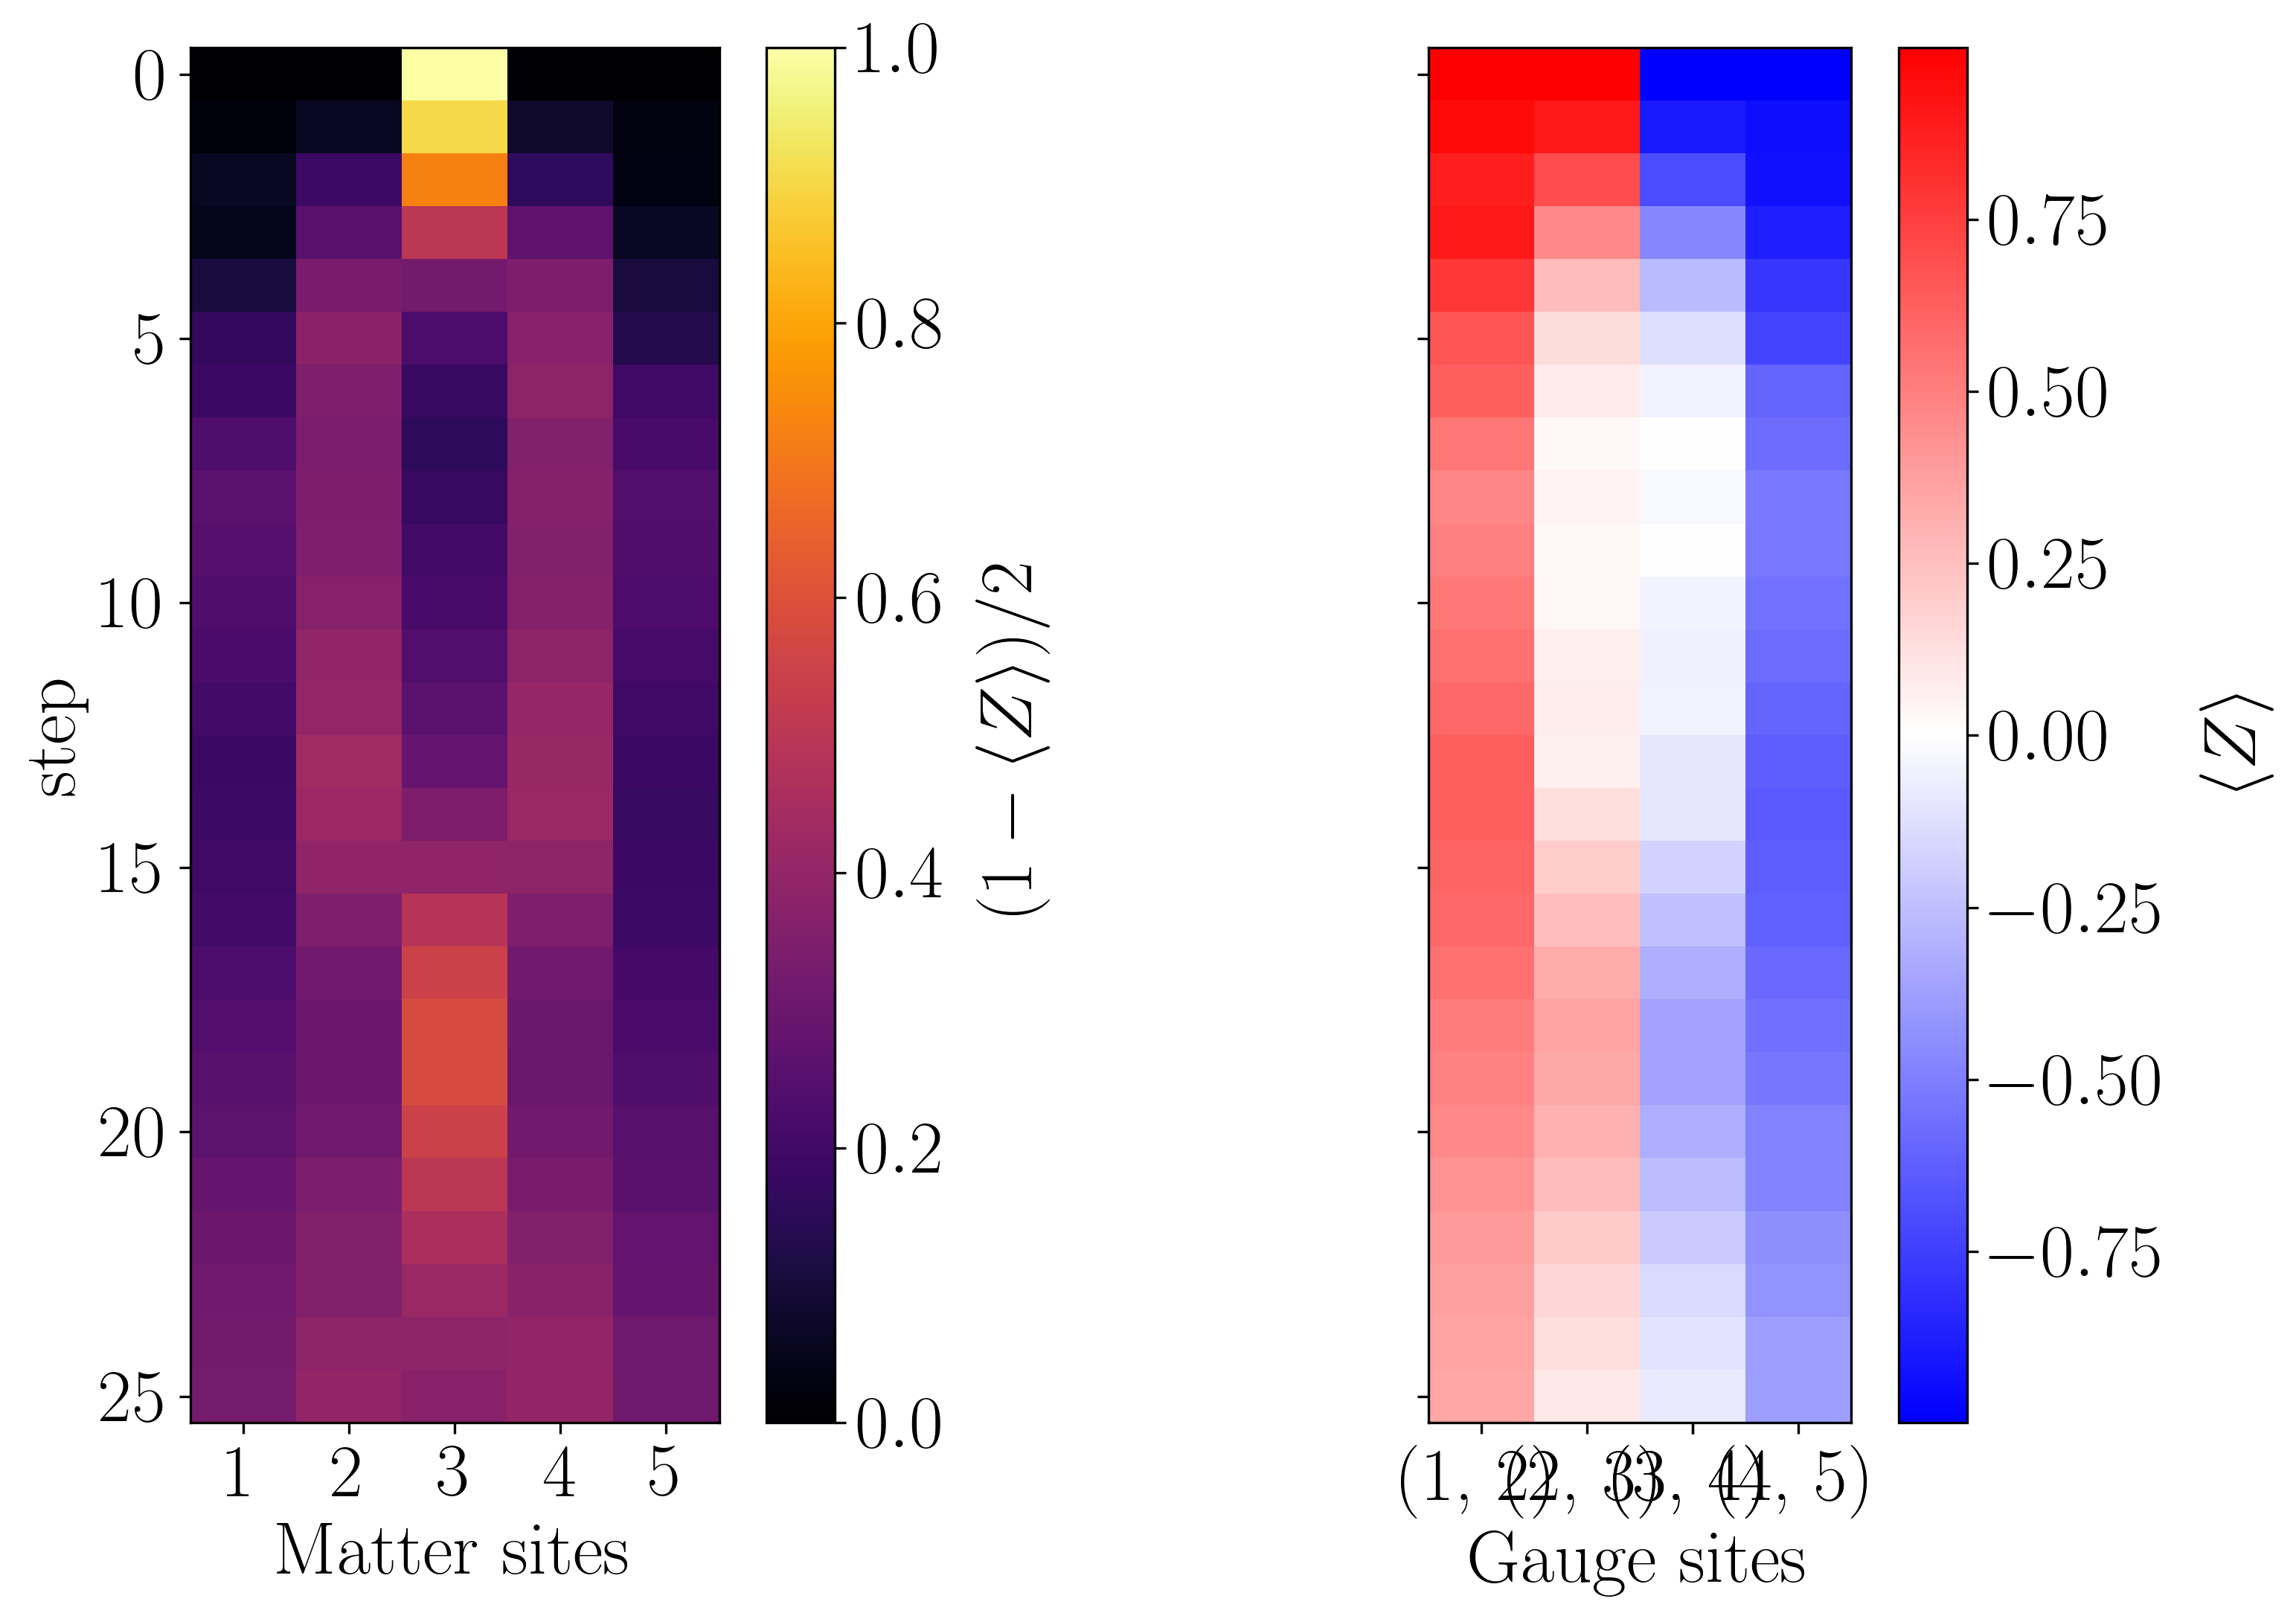

In [63]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(sim_observables_mpf[:, 1], cbar_range_matter=[0, 1])

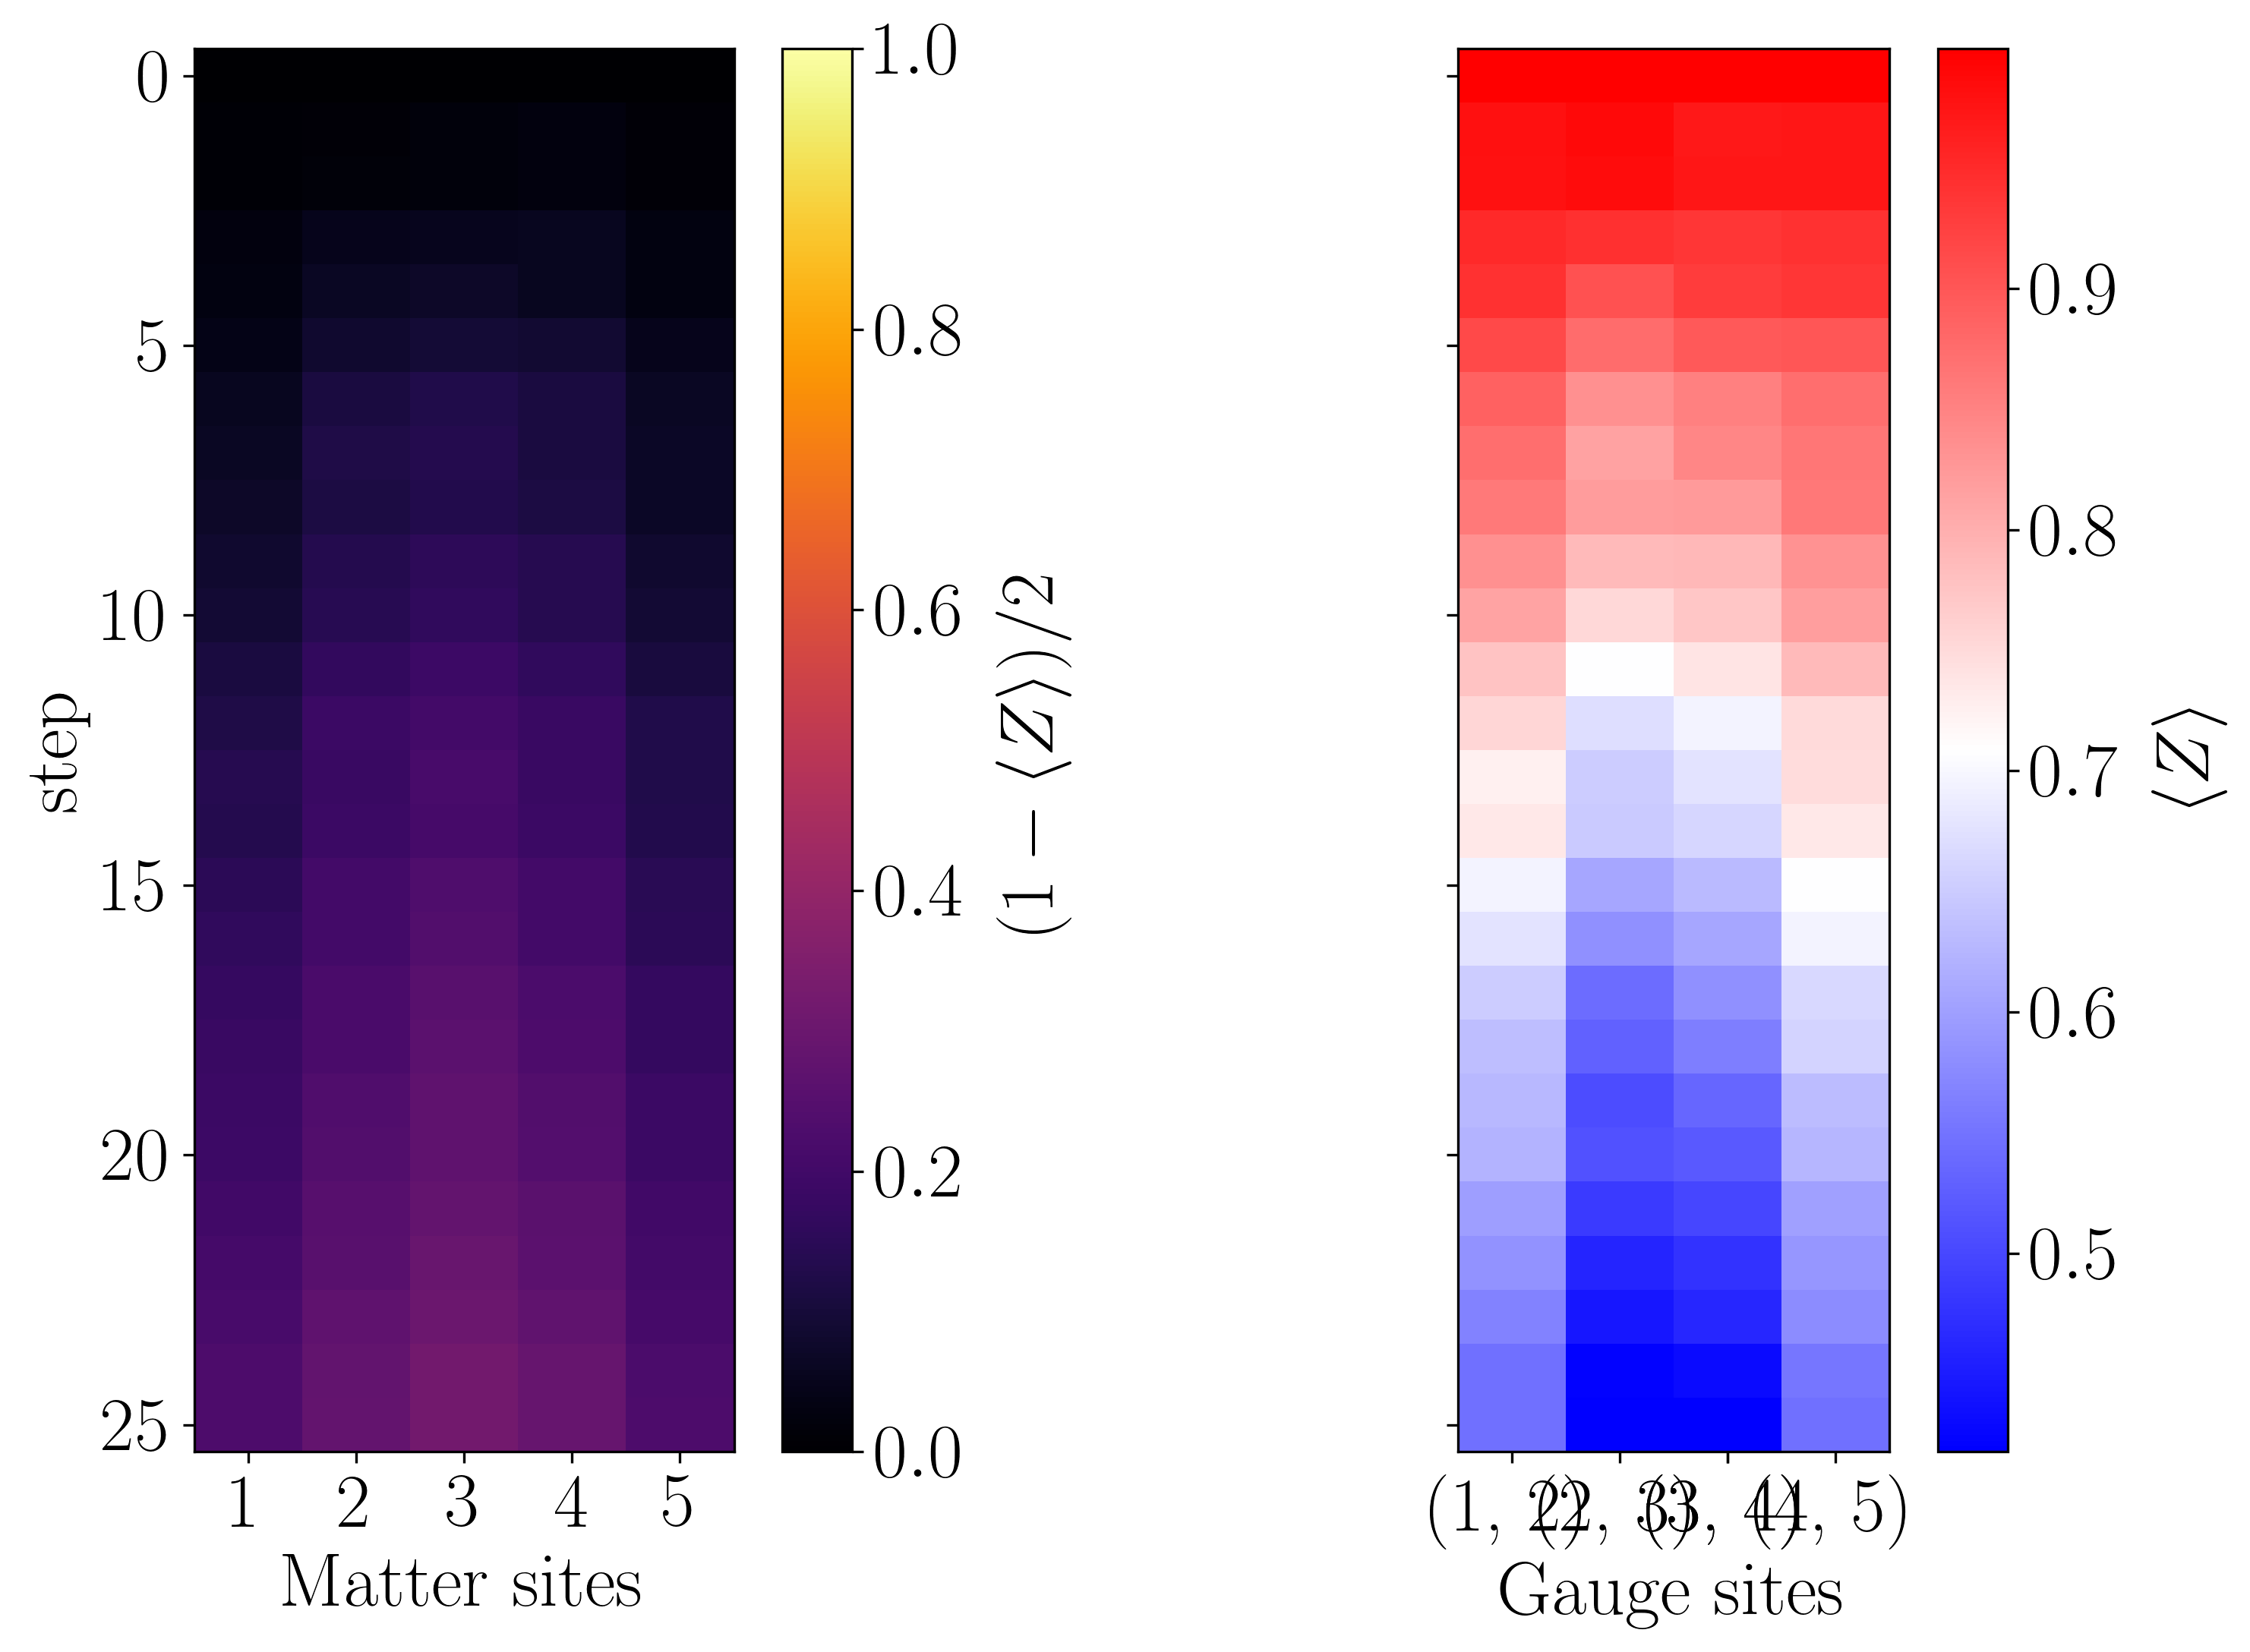

In [64]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(odr_observables_mpf[:, 1], cbar_range_matter=[0, 1])

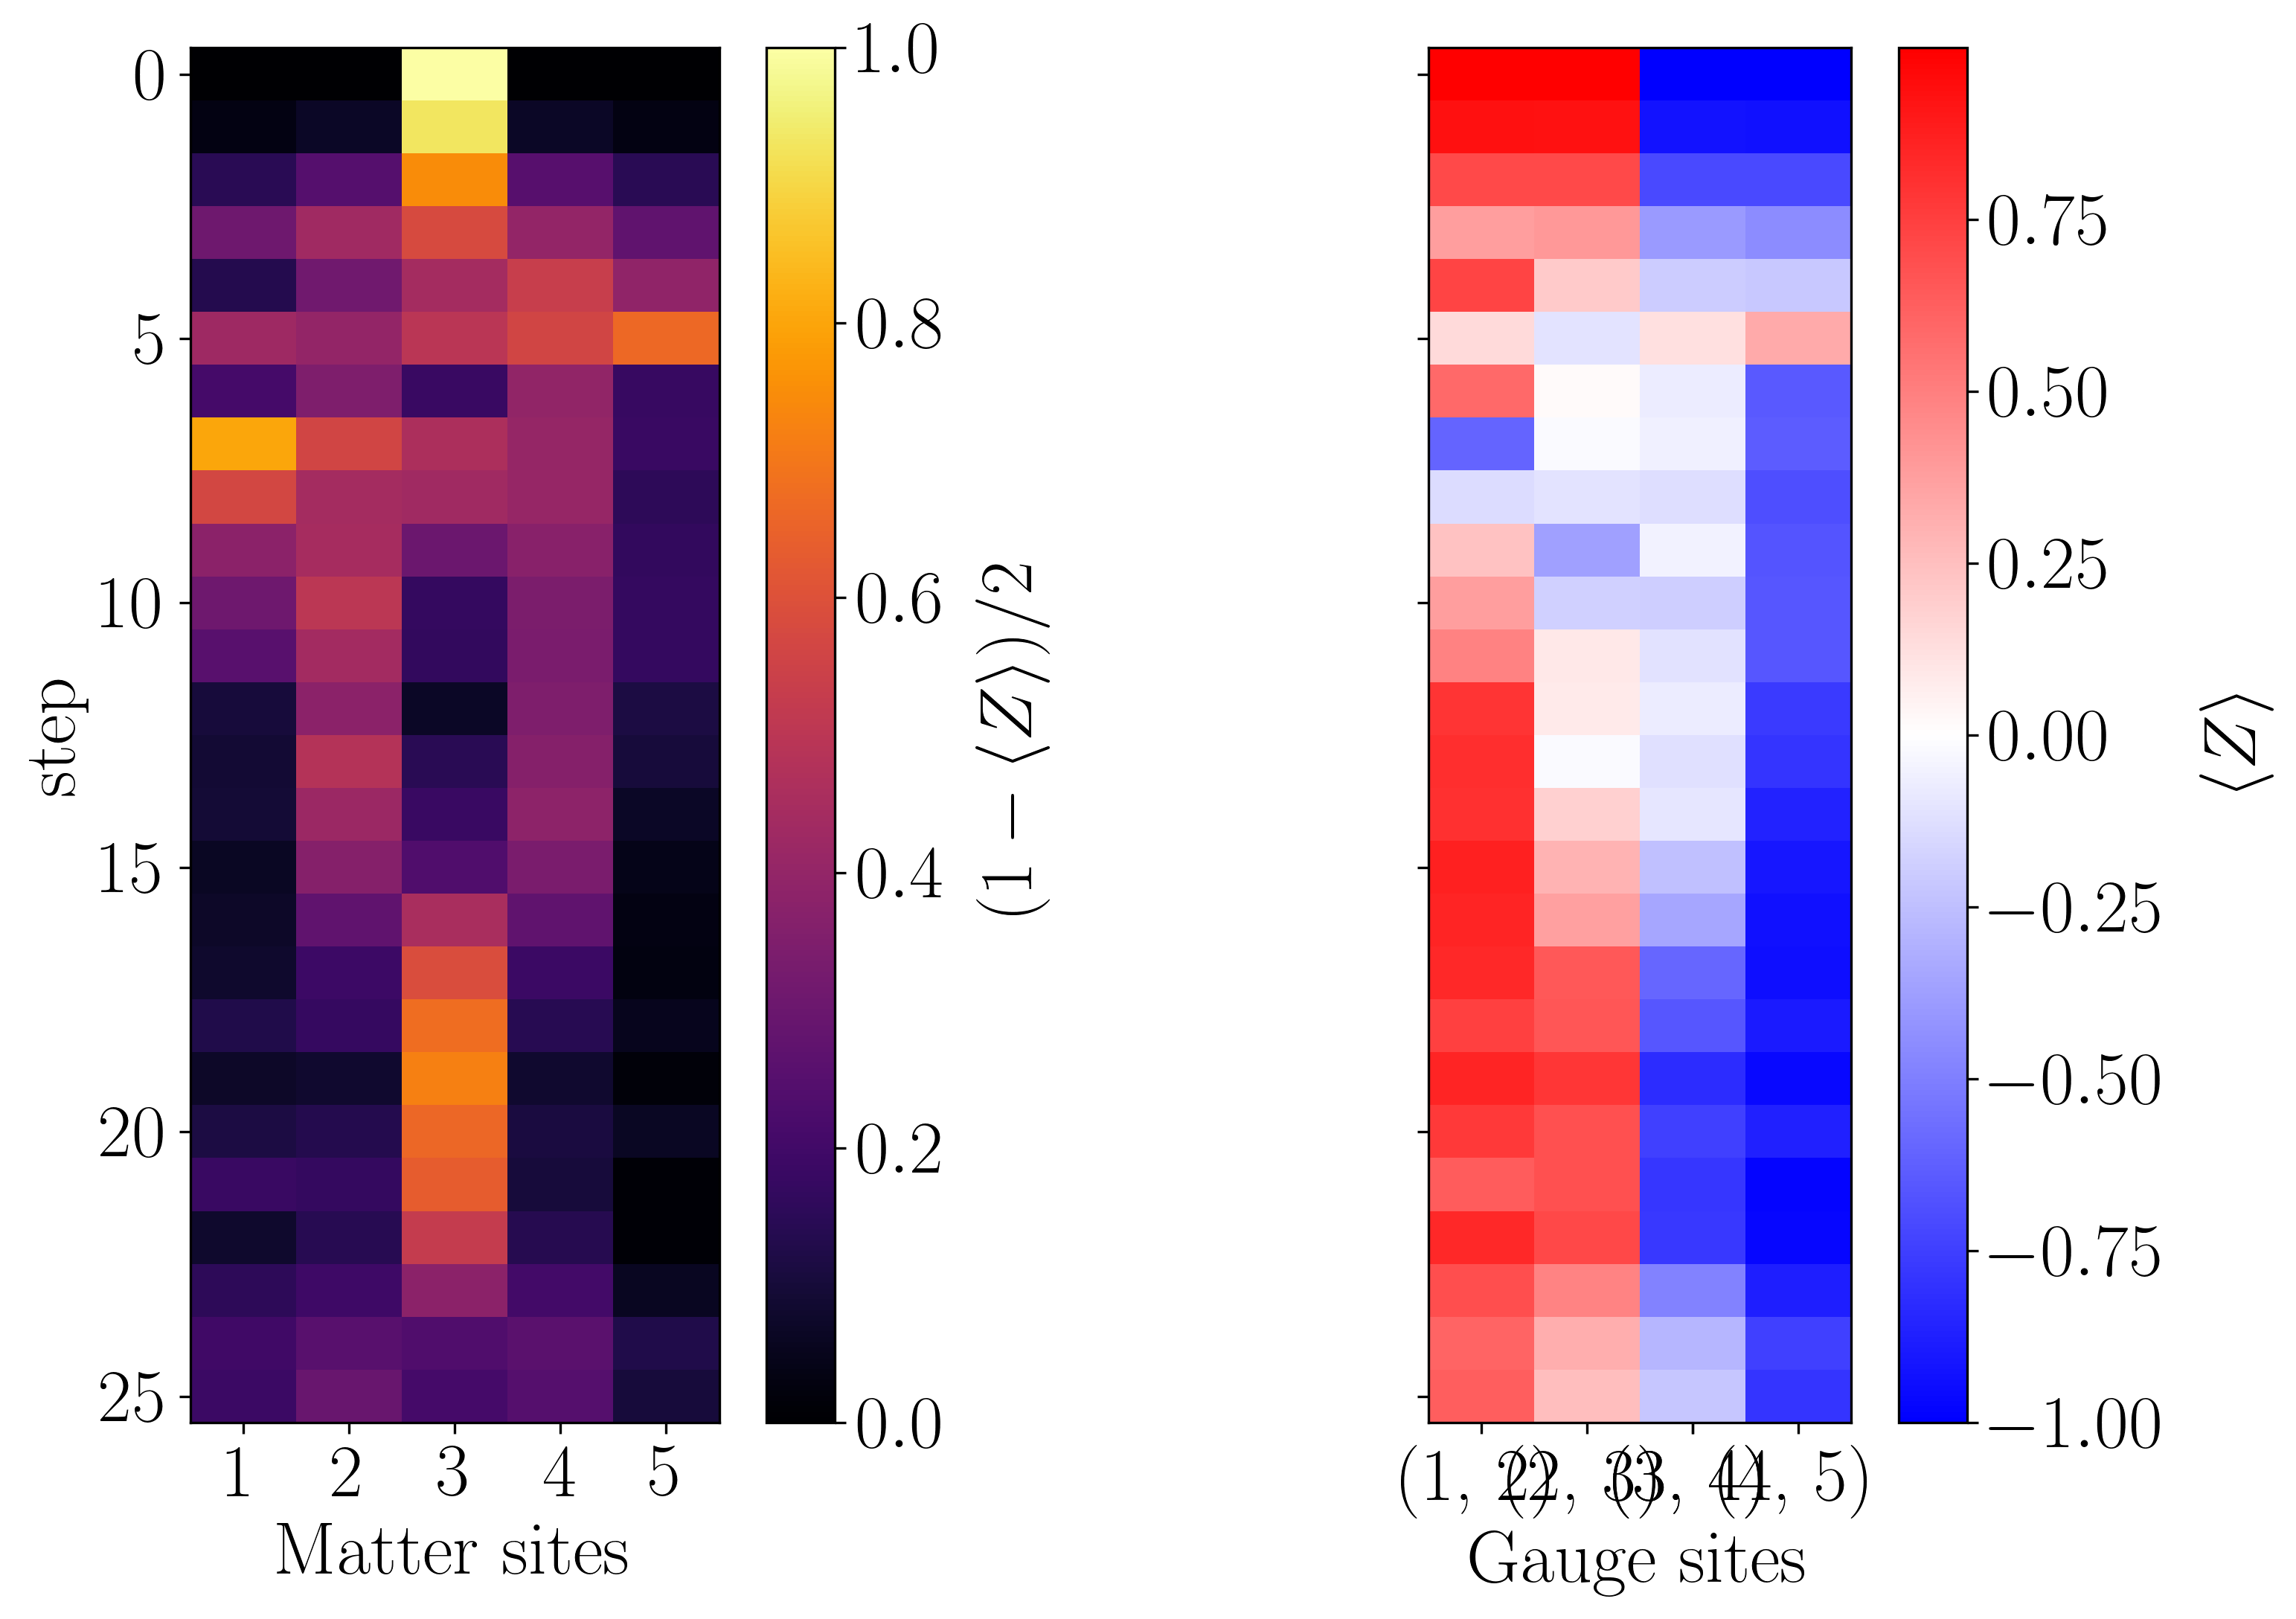

In [65]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_observables_mpf[:, 0], cbar_range_matter=[0, 1])

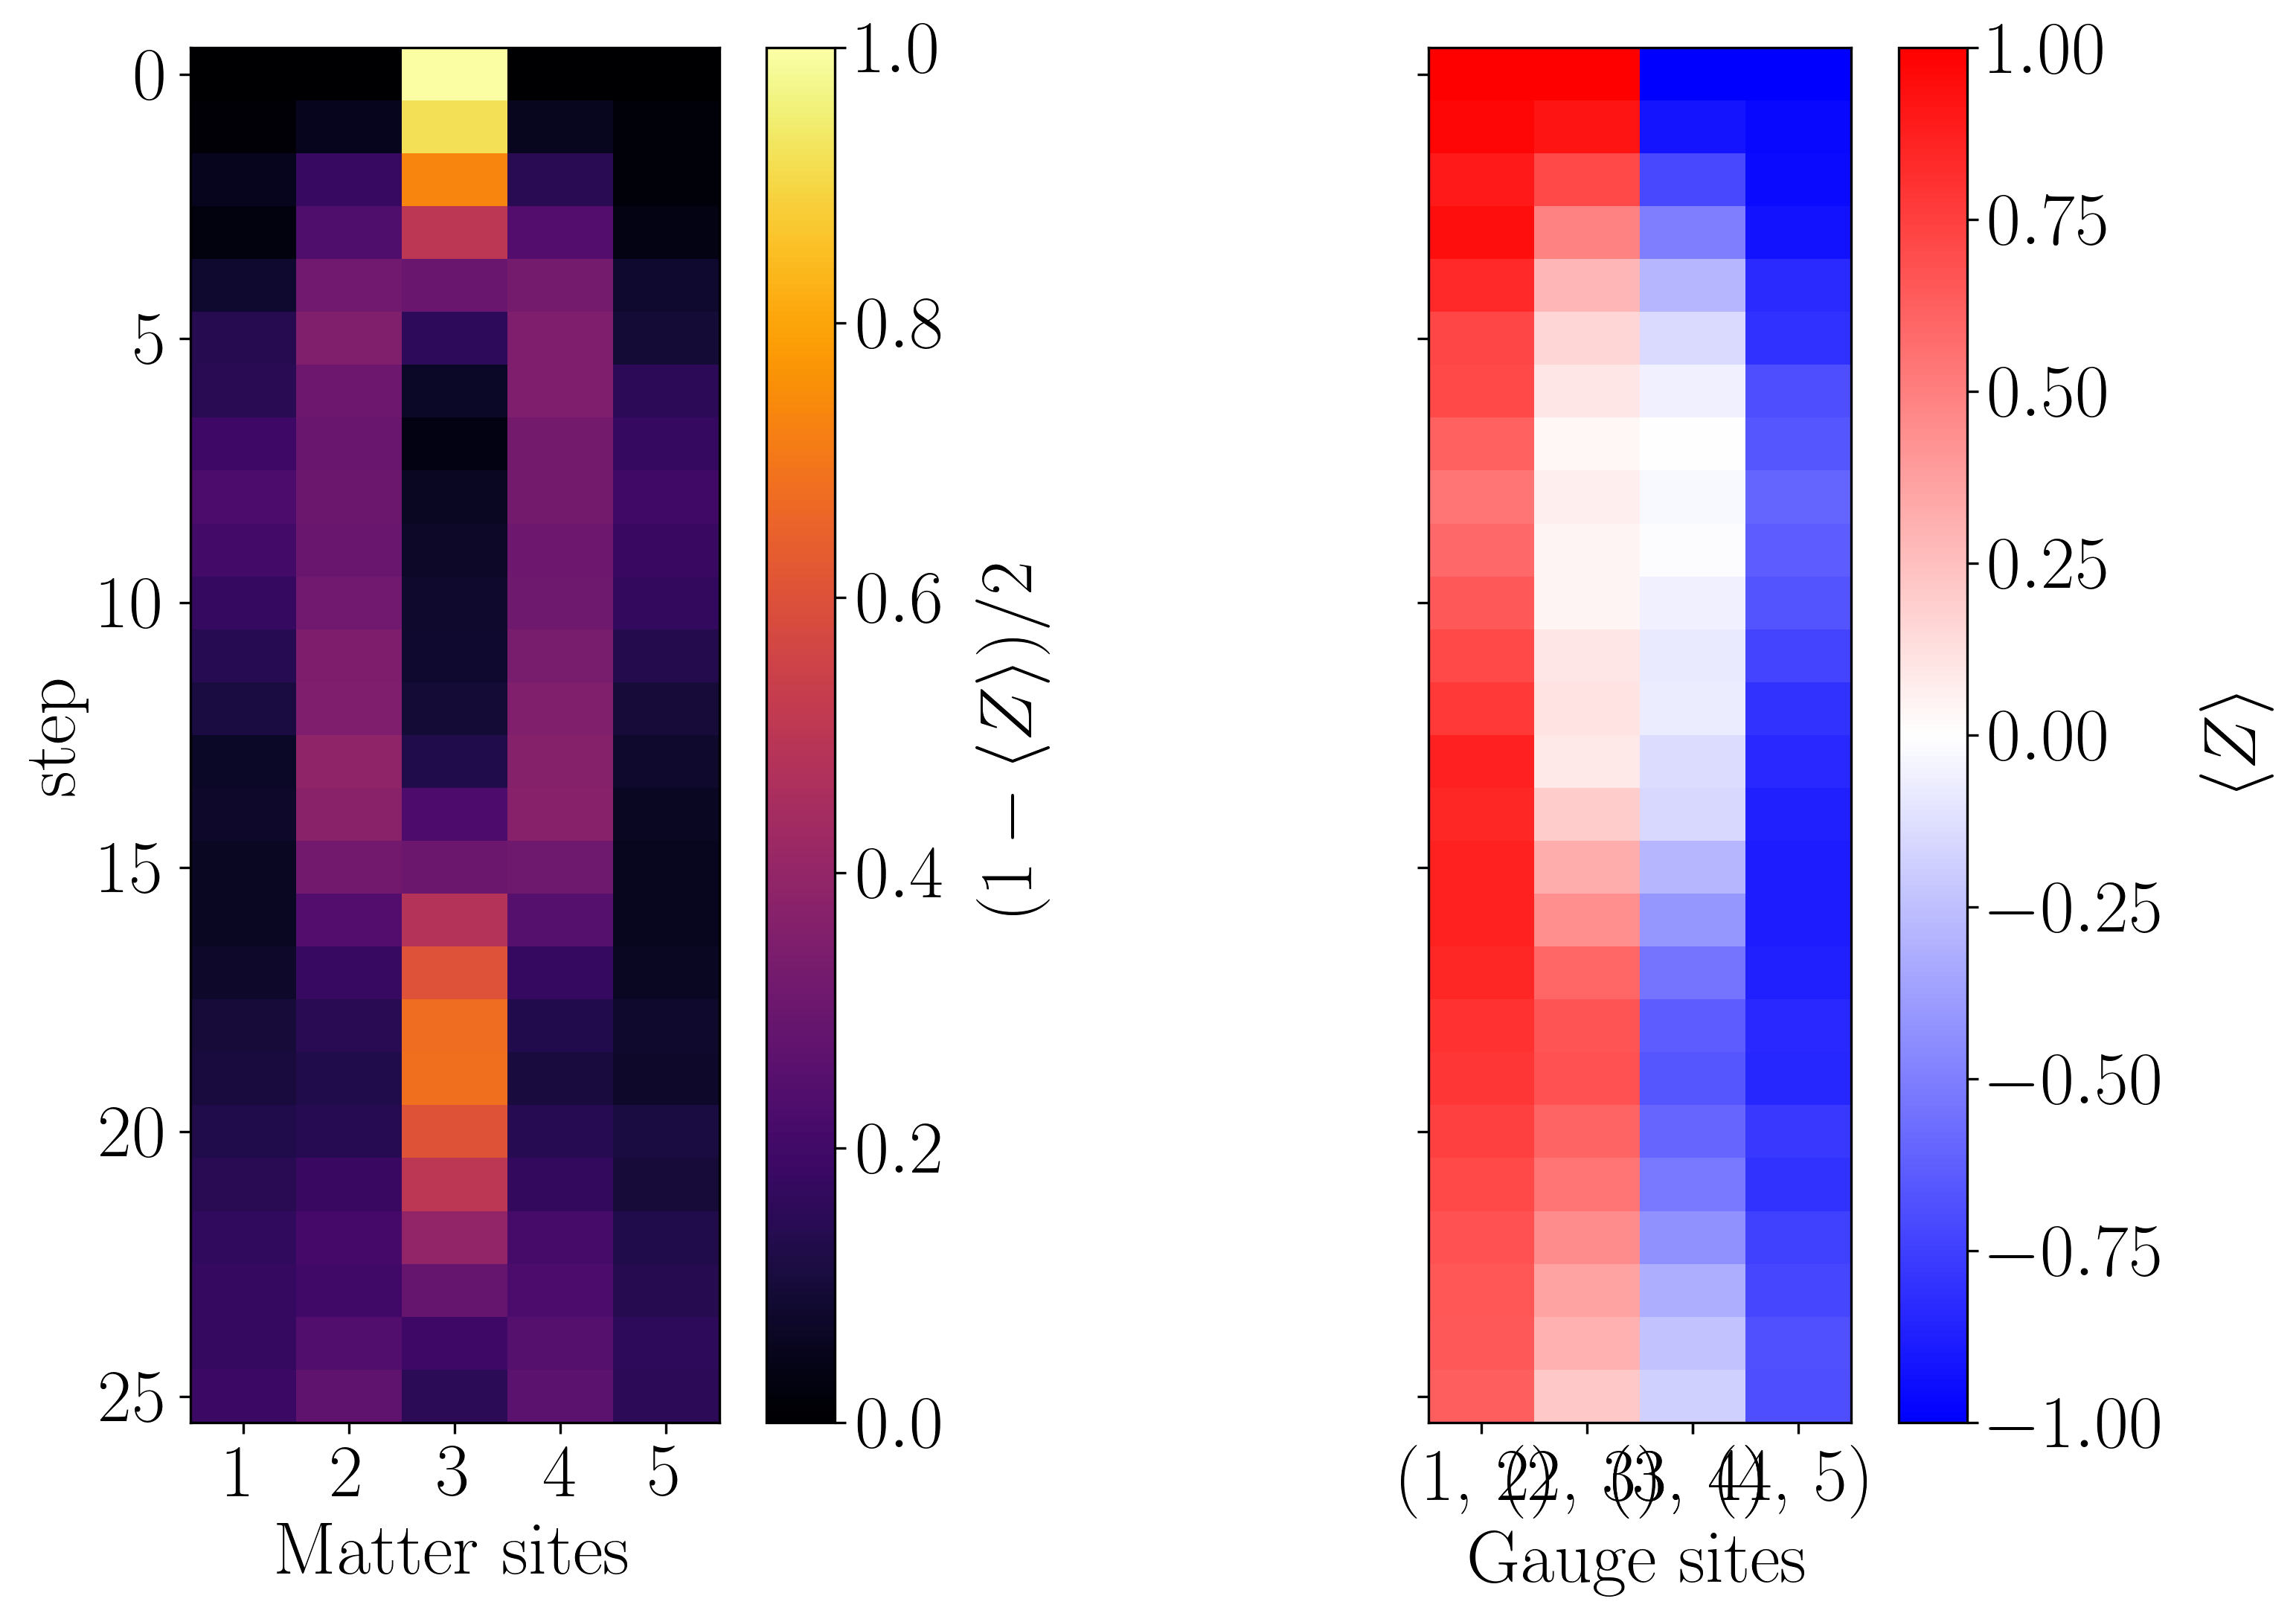

In [66]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_observables_mpf[:, 1], cbar_range_matter=[0, 1])

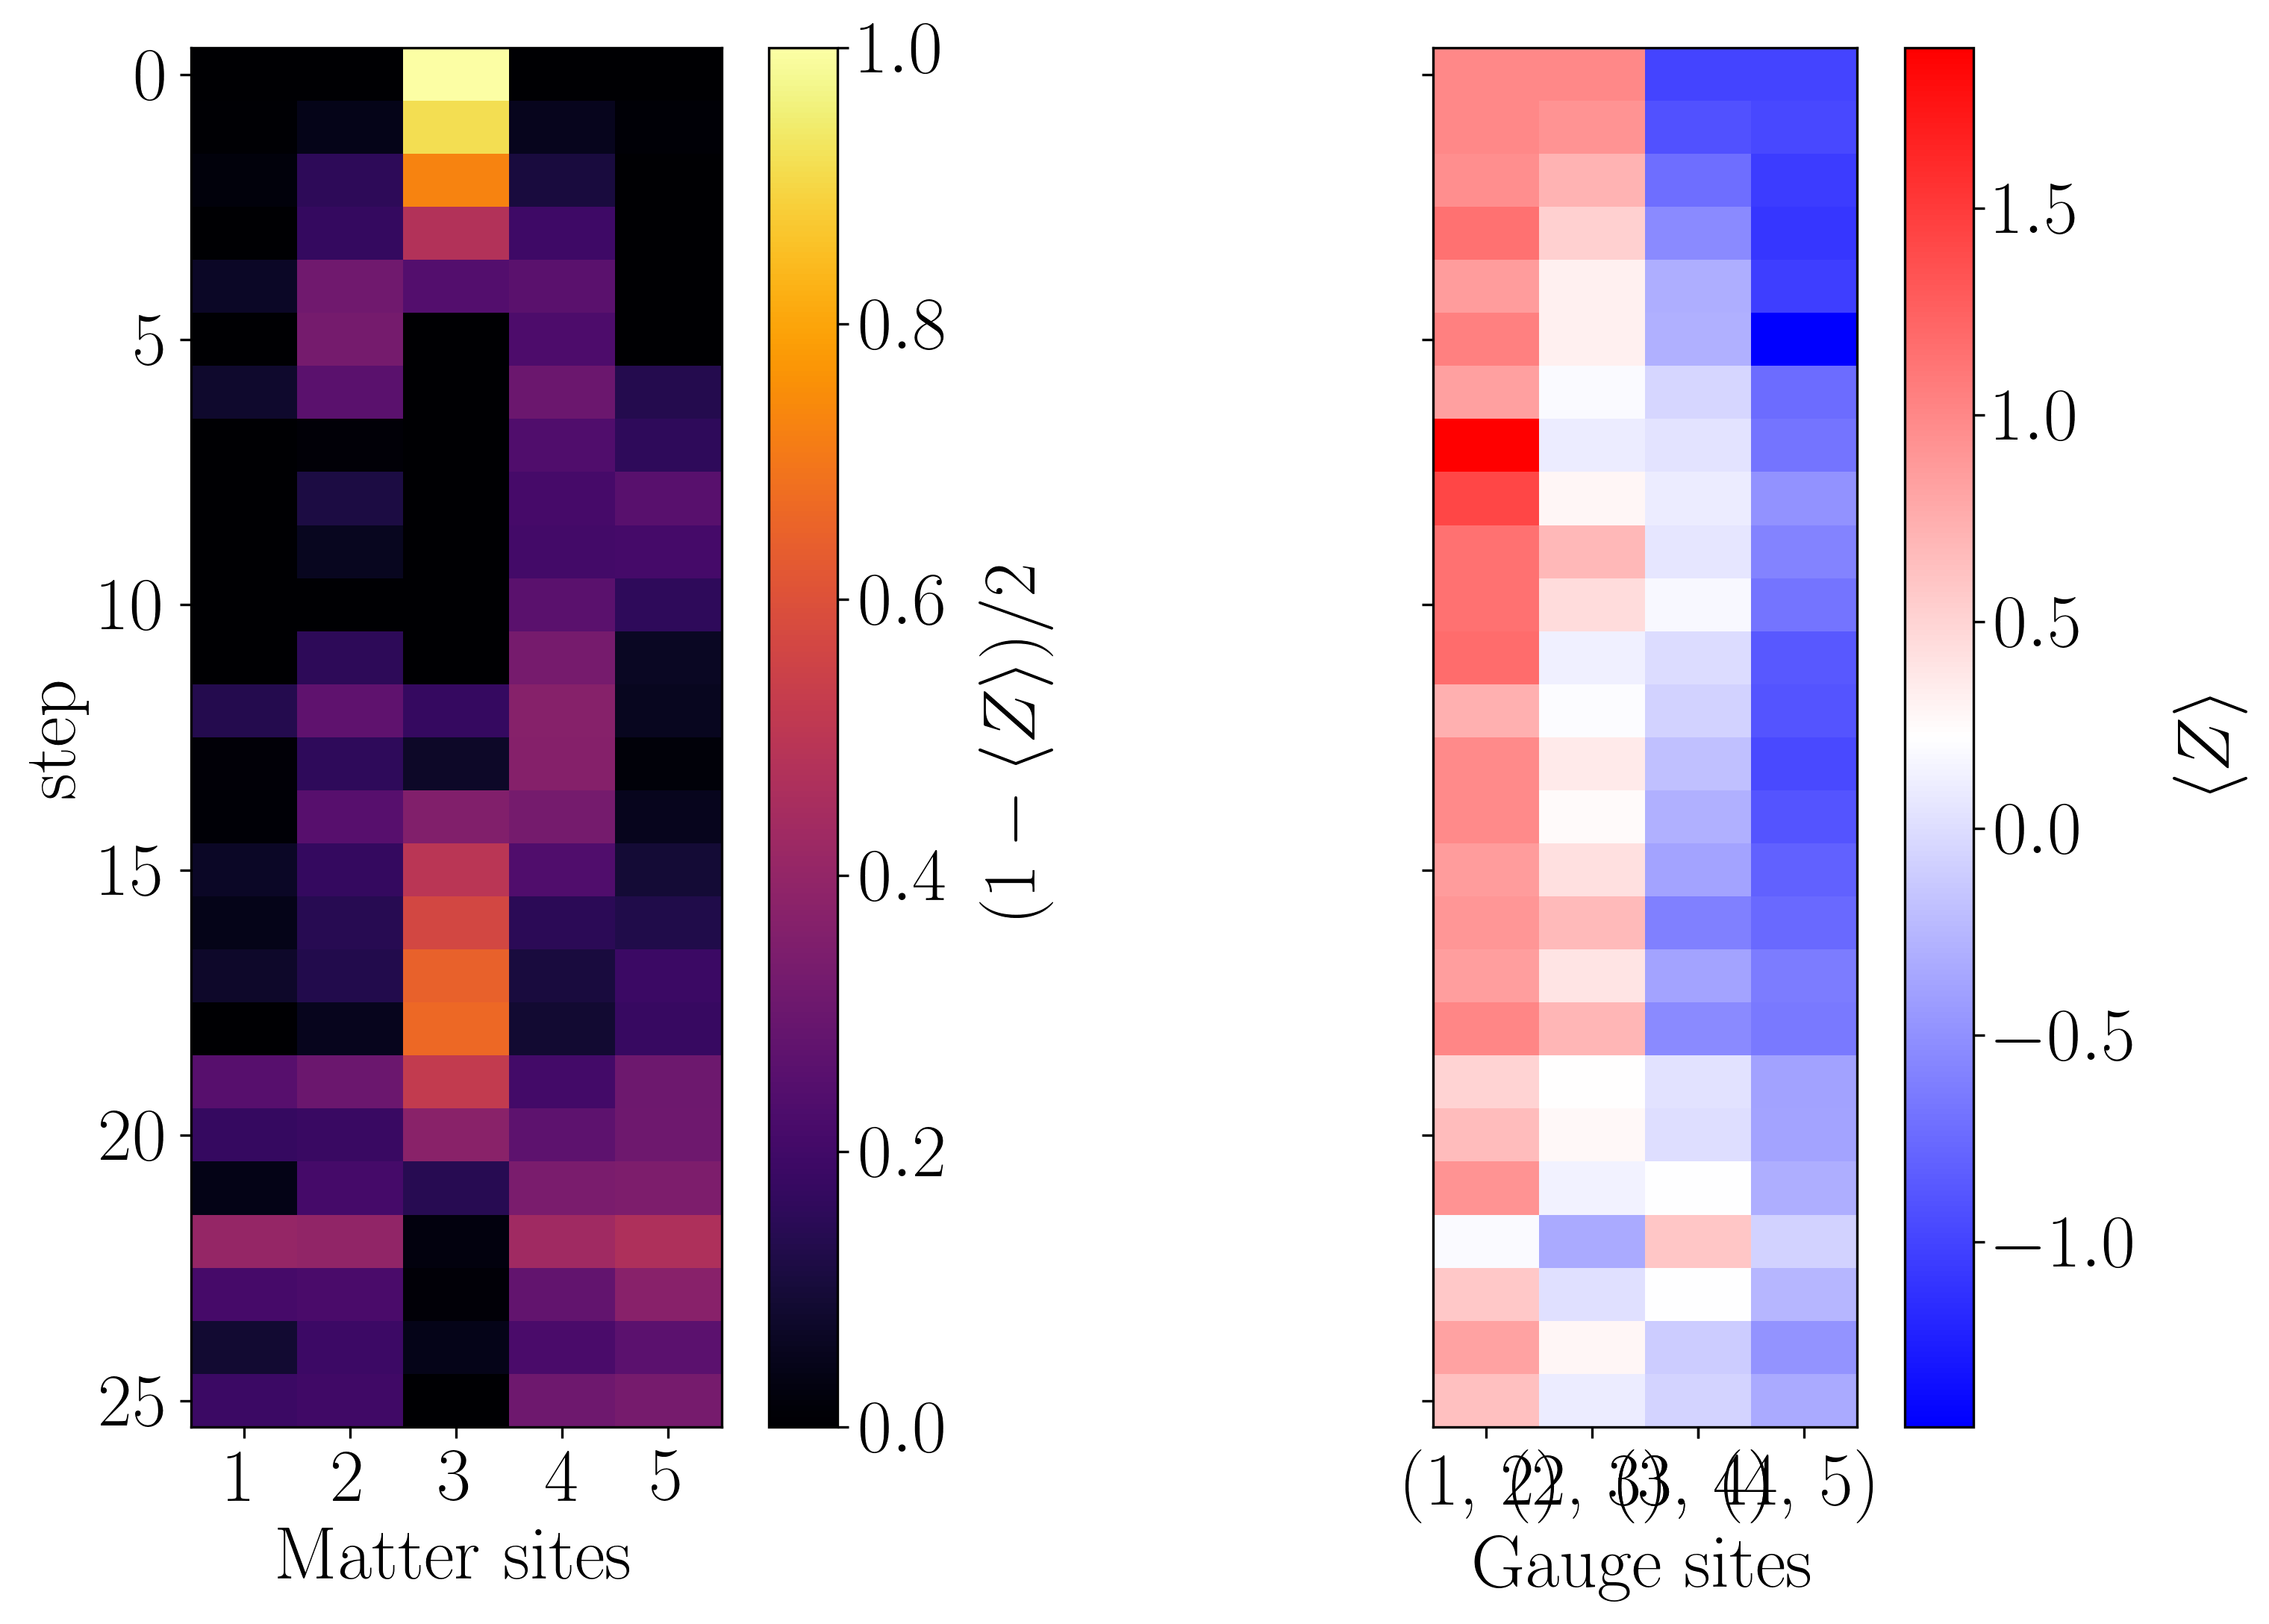

In [67]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_observables, cbar_range_matter=[0, 1])

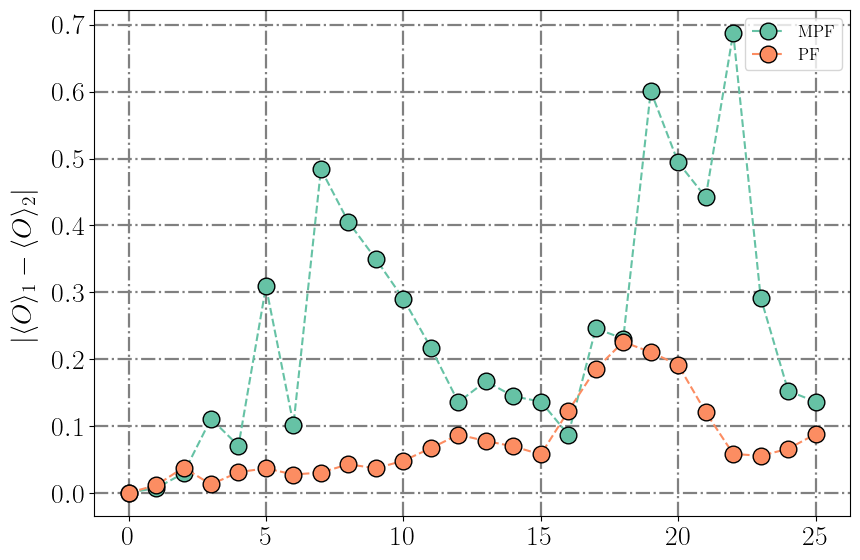

In [68]:
from utils.plotting import plot_mean_deviations

plot_mean_deviations([clean_observables, clean_observables_mpf[:, 1]], [exact_observables]*2, labels=["MPF", "PF"])